In [0]:
import os, sys
import pandas as pd
import numpy as np

import pyspark.sql.functions as F
from pyspark.sql import Window


from matplotlib import artist
import matplotlib.pyplot as plt
import seaborn as sns

# si1 / si2 functions are in data_pipeline/03_gold/seller_index
notebook_path = dbutils.notebook.entry_point.getDbutils().notebook().getContext().notebookPath().get()
sys.path.append(os.path.normpath("/Workspace" + os.path.dirname(notebook_path) + "/../data_pipeline/03_gold/seller_index"))

from si1_functions import prepare_orders, prepare_pit_reviews, create_dense_calendar, calculate_pit_metrics, create_daily_activity
from si2_functions import apply_bayesian_smoothing, apply_threshold_and_cap, calculate_penalties, generate_seller_index

fact_orders = spark.table("marketplace_olist.gold.fact_orders")
fact_order_items = spark.table("marketplace_olist.gold.fact_order_items")
fact_reviews = spark.table("marketplace_olist.gold.fact_reviews")

# Parameters

In [0]:
# PARAMETERS

# Rolling window: 60 days, from 61 to 2 days before the reference date
window_days = 60
lag_days = 2

# Global rates
global_late = 0.0907
global_claim = 0.1241

# Alphas
alpha_orders = 8
alpha_reviews = 8

# Thresholds
late_th = 0.01
claim_th = 0.05

# Maximum penalty (x Threshold)
late_cap = 20
claim_cap = 10

# K for logistic penalties

k_late = 10
k_claim = 10

config_params = {
    "alpha_orders": alpha_orders,
    "alpha_reviews": alpha_reviews,
    "global_late_rate": global_late,
    "global_claim_rate": global_claim,
    "late_th": late_th,
    "claim_th": claim_th,
    "late_cap": late_cap,
    "claim_cap": claim_cap,
    "k_late": k_late,
    "k_claim": k_claim
}

In [0]:
# fact_seller_metrics calculated with the si1 functions and the window defined above
pit_orders = prepare_orders(fact_orders, fact_order_items)
pit_reviews = prepare_pit_reviews(fact_reviews, fact_orders)
dense_calendar = create_dense_calendar(pit_orders, fact_order_items, window_days, lag_days)
fact_seller_metrics = calculate_pit_metrics(dense_calendar, pit_orders, pit_reviews, window_days)

fact_seller_metrics.createOrReplaceTempView("fact_seller_metrics")

# Seller Operational Index: Design and Construction Steps


# 1. Business Role of the Seller Index

The Seller Operational Index is a central metric in the Olist marketplace ecosystem. It serves two main purposes.

 - First, it acts as an incentive mechanism to influence seller behavior. Olist partially subsidizes shipping costs depending on seller performance. Sellers with higher operational reliability receive greater support in logistics costs, which encourages them to improve fulfillment quality and delivery performance.

 - Second, the index directly affects Olist’s revenue structure. Since Olist shares part of the logistics costs with sellers, the way the index is constructed determines how these costs are distributed across the marketplace. This introduces several important trade-offs.

If the index thresholds are too permissive, sellers can easily reach high performance tiers with minimal operational effort. While this may attract more sellers and increase marketplace supply, it can also generate higher operational costs for Olist. Late shipments and cancellations may lead to additional logistics expenses, increased customer service workload, and lower customer satisfaction. Conversely, if the thresholds are too demanding, the index may fail to provide effective incentives. Sellers may perceive the targets as unattainable therefore make no effort to improve their operational performance. In addition, the prospect of facing high shipping cost without a prospect of cost reduction may discourage them from entering the marketplace in the first place, preventing profitable sales transactions for both OLIST and the sellers.

The challenge is therefore to design thresholds that are demanding yet attainable, aligning seller incentives with the platform’s operational efficiency and profitability.

# 2. Determinants of Seller Performance
The seller index is constructed from 2 operational indicators reflecting different aspects of seller reliability.

## 2.1 Late Shipments

Late shipments represent the most critical operational metric for Olist.

In the marketplace logistics model, Olist acts as an intermediary between sellers and external logistics partners. As a result, Olist has a dual commitment:

 - to customers, who expect deliveries within the estimated timeframe

 - to logistics partners, who operate under predefined service agreements

When a seller dispatches a package late, several issues may arise. The logistics partner may need to adjust delivery schedules, potentially increasing operational costs. In some cases, delays can also disrupt contractual service guarantees within the logistics chain.

For these reasons, late shipments typically receive the highest weight in the seller index.

## 2.2 Customer Complaints and Reviews

The third dimension of seller performance is customer complaints and dissatisfaction.

Customer experience in the Olist dataset is primarily measured through the review_score, which ranges from 1 to 5.

Seller satisfaction can be evaluated using two alternative approaches:

 - the average review score

 - the proportion of low ratings (for example ratings ≤ 2)

The second approach often provides a more robust signal because it captures extreme dissatisfaction events, which are particularly harmful to marketplace reputation. Review scores not only provide a numerical summary of customer satisfaction, but also a signal of the seller's after-sales service. Reviews are computed ex-post and review scores for an order_item can be changed by the customer anytime, offering a consistent snatshop of customer satisfaction and seller's after-sales service.

However, it is important to note that review scores reflect the entire purchase experience, meaning they may be influenced by the other operational metrics such as late shipments.

## 2.3 Other determinants: Order Cancellations

Order cancellations by the seller are closely linked to inventory management and order lifecycle processes. 

Olist centralizes order processing and inventory synchronization across multiple marketplaces. Maintaining accurate inventory data is therefore essential to prevent overselling and ensure consistent order fulfillment. 

Frequent cancellations from a seller may indicate poor inventory management by sellers, which can negatively affect both customer trust and marketplace reliability. That is why cancellations are one of the key factors considered by Olist while constructing the official seller index metric.  

In our dataset, cancellations by seller are registered in the `fact_orders` table as order_status = 'unavailable'. Orders with that status lack item/seller records in the `fact_order_items` table, so this metric is unmeasurable at seller level and won't be included in our analysis.

# 3. Designing the Seller Index


##3.1 - `fact_seller_metrics` – Daily seller performance metrics

#### Rolling Window Selection


The first step in constructing the Seller Index is to compute daily performance metrics for every active seller. Building the index on a daily basis is important because the marketplace is dynamic: sellers enter and leave the platform, and their operational performance evolves over time. A daily structure ensures that the index reflects the current operational state of each seller at any given point in time.

A key methodological requirement in this step is to avoid the use of future information when computing historical metrics. At each reference date, the index must only rely on information that would have been available at that moment. 

For this reason, all performance indicators are calculated using rolling windows that look backwards from the reference date.

Discussion about the window selection for the data is analyzed in segment `5.1 - Window Selection` of this notebook. Based on the empirical analysis, a **60 days window** is sellected both for orders and for reviews.

## 3.2 - Seller Index Construction Phases

Based on the reference metrics calculated, the objective is to build a seller index that consistently reflects the reliability of each seller at any given point in time, leveraging the historical data available.

For this index to be meaningful from a business perspective, it must address several key challenges. First, it should prevent low-volume or new sellers from being disproportionately penalized due to early adverse events, which could discourage platform adoption. At the same time, it must ensure that underperformance is still properly captured, maintaining the credibility of the system. Additionally, the index should be responsive enough to reflect recent behaviour, while remaining stable and robust against short-term volatility.

To achieve this balance, a series of adjustments to the base metrics are introduced, including smoothing techniques, the application of thresholds and caps, and the use of alternative functional forms for penalization. These modifications aim to improve both the interpretability and the economic relevance of the index.

From a business standpoint, this framework enables OLIST to compare different index configurations and understand how design choices impact seller evaluation. It allows for a more informed calibration of incentives, aligning seller behaviour with strategic objectives such as service quality and customer satisfaction.

Moreover, by linking the index to financial outcomes, OLIST can assess the economic implications of different incentive schemes, ensuring that the chosen approach not only promotes reliability but also improves long-term value creation.


### 3.2.1 - Bayesian smoothing
Marketplace datasets typically exhibit a long-tail distribution of sellers, in which a small number of sellers generate a large share of orders, while many sellers operate at very small volumes.

As we have seen, OLIST is not an exception. Because of its nature (specialized in connecting smaller sellers to wider on-line markets) the long-tail of OLIST is notably pronounced. The percentile 75 of sellers has sold on average 8 orders in a window of 60 days.

Because of this structure, raw performance rates become extremely unstable for low-volume sellers. For example, a claim rate of 100% when a seller has one order is not very informative about seller quality. Instead, they are simply the result of small sample sizes.

Without correction, this leads to several problems:

 - extreme volatility in seller scores

 - strong penalization of new sellers

 - misleading comparisons between sellers with very different volumes of sales

To address this issue, the index applies Bayesian smoothing. This technique reduces the volatility of rates observed for sellers with limited activity while preserving the observed performance of high-volume sellers.

This formulation can be interpreted as adding **α** virtual observations to each seller’s data, with those observations distributed according to the global marketplace rate. Sellers with very small sample sizes therefore remain close to the marketplace average, while sellers with many observations gradually converge toward their own empirical rate.

The global benchmark rates used in the smoothing process correspond to the average performance ratios of the platform for the period analyzed:
 - Late shipment rate: 0.0907
 - Claim rate: 0.1241

These values were calculated directly from the aggregated metrics of the previous table (`fact_seller_metrics`) and represent the baseline operational performance of the marketplace.

In [0]:
# Global Rates
display(spark.sql(f"""
SELECT
    ROUND(SUM(late_to_carrier_{window_days}d) / SUM(delivered_to_carrier_{window_days}d),4) AS global_late_rate,
    ROUND(SUM(claims_{window_days}d) / SUM(reviews_{window_days}d),4) AS global_claim_rate
FROM fact_seller_metrics
"""))

global_late_rate,global_claim_rate
0.0907,0.1241


### 3.2.2 - Threshold and Cap


Thresholds and caps act as the key link between business objectives and the intensity of the penalties embedded in the index. Thresholds define the acceptable operational standards for the platform—serving as the point at which seller performance starts to be penalized—while caps establish an upper bound to that penalization, preventing extreme values from disproportionately distorting the index.

The selected thresholds are as follow:

 - Late shipments: 1% (aligned with Olist guidelines)

 - Claims: 5% (defined in this project due to differences in the claim metric construction)

To preserve a consistent business interpretation, caps are set proportionally to thresholds (currently 20x for late shipments and 10x for claims), ensuring a stable relationship between acceptable performance levels and maximum penalization.

Sellers with ratios at or below the threshold receive the maximum score of 1 in the reference metric. Those with ratios above the cap receive a score of 0.

### 3.2.3 - Fuctional Form of Penalties 

The normalization process produces a continuous and monotonic score that smoothly increases from 0 at the smoothed threshold to 1 at the upper limit.

Once normalized scores are available, the next step is to transform them into penalty components that reflect how deviations from the target performance level should affect the final Seller Index.

The function used to traze the transition between those limits will determine how different sellers are punished. To explore how different penalty structures affect the final index, three functional forms are considered:

 - **Linear penalty** - penalty increases proportionally with the deviation from the target.
 - **Quadratic penalty** - penalizes large deviations more strongly while remaining relatively forgiving for small deviations near the threshold.
 - **Logistic penalty** - penalizes even small deviations from the threshold relatively strongly.

These three functional forms represent different policy choices regarding how aggressively the marketplace should penalize underperforming sellers. By modifying the shape of the transition between the threshold and the cap, these functions make it possible to design policies that distribute penalization differently across performance ranges. This provides a flexible framework to calibrate how quickly the index reacts to deviations from acceptable standards and how strongly it distinguishes between moderate and severe underperformance, ensuring alignment with the platform’s operational and strategic objectives.

NOTE: To maintain business consistency and readibility of the reference metrics for the sellers, penalties start being applied after the reference rate surpasess the corresponding threshold (and not the smoothed version of said threshold). Consequently, the effective penalty function is not continuous. It has a jump when the ratio of reference is equal to the threshold.

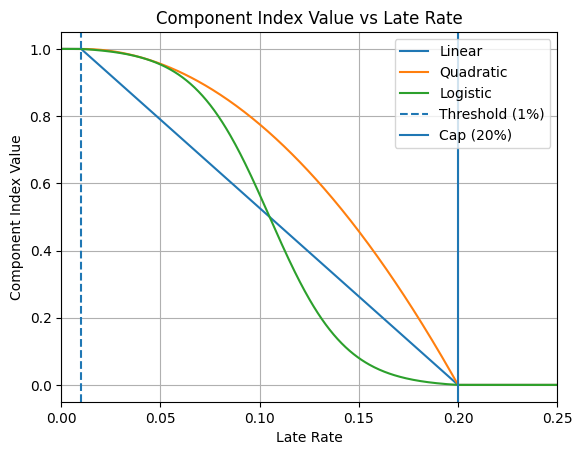

In [0]:
# Parameters
threshold_example = 0.01
cap_example = 0.20
k_example = 10

# Zooming range of X axis.
x = np.linspace(0, 0.25, 500)

# Normalization between threshold and cap
z = (x - threshold_example) / (cap_example - threshold_example)

# Clip to  range [0,1]
z_clipped = np.clip(z, 0, 1)

# --- LINEAR ---
linear_score = np.where(
    x <= threshold_example, 1,
    np.where(x >= cap_example, 0, 1 - z_clipped)
)

# --- QUADRATIC ---
quadratic_score = np.where(
    x <= threshold_example, 1,
    np.where(x >= cap_example, 0, 1 - z_clipped**2)
)

# --- LOGISTIC ---
logistic_raw = 1 / (1 + np.exp(-k_example * (z_clipped - 0.5)))

logistic_min = 1 / (1 + np.exp(-k_example * (0 - 0.5)))
logistic_max = 1 / (1 + np.exp(-k_example * (1 - 0.5)))

logistic_scaled = (logistic_raw - logistic_min) / (logistic_max - logistic_min)

logistic_score = np.where(
    x <= threshold_example, 1,
    np.where(x >= cap_example, 0, 1 - logistic_scaled)
)

# --- Plot ---
plt.figure()

plt.plot(x, linear_score, label="Linear")
plt.plot(x, quadratic_score, label="Quadratic")
plt.plot(x, logistic_score, label="Logistic")

# Reference lines
plt.axvline(threshold_example, linestyle='--', label="Threshold (1%)")
plt.axvline(cap_example, label="Cap (20%)")

# Labels
plt.title("Component Index Value vs Late Rate")
plt.xlabel("Late Rate")
plt.ylabel("Component Index Value")

plt.xlim(0, 0.25)

plt.legend()
plt.grid()

plt.show()

### 3.2.4 - Seller Index & Financial Scenarios

The final Seller Index is computed by aggregating the penalty components from each metric.

Operationally, *late shipments* are considered the most critical performance issue, as they directly affect delivery reliability and customer satisfaction. For this reason, the late shipment component receives double weight in the final penalty calculation. 

The total penalty is therefore calculated as a weighted average of late-delivery and claim penalties, with a 2:1 ratio. The result is rescaled so that the maximum weighted penalty is 4:

$$
\text{Total Penalty} = \frac{4}{3} \times (2 \times \text{late}'{\text{component}} + \text{claim}'{\text{component}})
$$

The Seller Index is then constructed as a discrete score between 1 and 5, mirroring the official metric from Olist:

$$
\text{Seller Index} = \max(1, 5 - |\text{Total Penalty}|)
$$

The index calculation is performed three times, once for each functional form of the components (linear, quadratic, and logistic), allowing the impact of different penalty structures to be analyzed.

Finally, the Seller Index determines the percentage of shipping costs covered by Olist, according to the platform’s current operational policy: 

| Seller Index | Olist Shipping Coverage |
| ------------ | ----------------------- |
| 1–2          | 15%                     |
| 3            | 30%                     |
| 4            | 40%                     |
| 5          | 50%                     |

This mechanism directly links operational performance with financial incentives, encouraging sellers to maintain high service quality.

### 3.2.3 - Seller Index consistency

The seller index must maintain consistency at both the micro and macro levels.

At the individual level, the seller index should function as an effective incentive mechanism. The scoring system must be sensitive enough to encourage operational quality improvements, while avoiding excessively punitive behavior for isolated or initial seller failures. Since shipping costs directly affect seller profitability and pricing decisions, the index should reflect a realistic balance between accountability and economic viability. Overly aggressive penalties may discourage seller participation or generate incentives that are misaligned with long-term platform health. A theorical analysis of the evaluation of a seller under different scenarios is performed in section `4. Theorical Analysis: Modelling individual seller evaluation`.

At the aggregate level, the system must also preserve meaningful differentiation across the seller population. An excessively lenient index would reduce its informational value by concentrating most sellers near the maximum score, limiting its usefulness for operational prioritization and incentive design. Additionally, the calibration of the index must remain aligned with the company’s financial objectives: a higher proportion of sellers receiving top scores directly increases the shipping subsidy cost assumed by OLIST. Consequently, parameter selection should balance seller incentives, metric sensitivity, and the overall economic sustainability of the program. An analysis of the historic values of the seller index and its evolution over time is performed in section `5. Empirical Analysis`.

# 4. Theorical Analysis: Modelling individual seller evaluation

Before applying the Seller Index to the Olist dataset, a theoretical analysis is conducted using synthetic scenarios to validate the behavior of its components under different operational conditions. Controlled combinations of transaction volumes and incident levels (late deliveries and claims) are generated, allowing the impact of each variable on the resulting score to be assessed in isolation.

The objective of this phase is to verify that the parameters used in the construction of the index produce outcomes that are consistent with the design principles defined for the metric. Particular attention is given to the smoothing parameter (alpha), whose purpose is to prevent excessive penalties arising from isolated incidents or sellers with a limited number of transactions within the analysis window, while preserving the index's ability to identify and penalize persistently poor performance.

To achieve this, the sensitivity of the different index components is evaluated across a range of alpha values. The analysis examines how penalties evolve under different combinations of incident rates and transaction volumes. Results indicate that alpha values between 3 and 8 provide an appropriate balance between stability and responsiveness. Within this range, the index substantially reduces the volatility associated with small sample sizes while remaining sufficiently sensitive to penalize sellers whose rates of late deliveries or claims remain consistently high as transaction volumes increase.

Based on these findings, **an alpha value of 8** is selected for the late delivery and claims components.

## 4.1 - Synthetic Scenario Generation

In [0]:
# SIMULATION GRID

# Orders grid (rows)
orders_grid = [1, 2, 3, 5, 8, 13, 20, 30, 50]

# Triggers (Columns)
late_triggers = [1, 3, 5, 8, 12]
claim_triggers = [1, 3, 5, 8, 12]

# Alphas
alphas = [1, 3, 5, 8, 15, 30]

In [0]:
import itertools

rows = []

for orders, triggers in itertools.product(orders_grid, late_triggers):
    for alpha in alphas:
        rows.append((orders, triggers, alpha))

df_late = spark.createDataFrame(rows, ["orders", "late_shipments", "alpha"])

In [0]:
# Late Shipments

df_late = df_late.withColumn(
    "late_rate",
    (F.col("late_shipments") / F.col("orders"))
)

df_late = df_late.withColumn(
    "smoothed_late_rate",
    (F.col("late_shipments") + F.col("alpha") * F.lit(global_late)) /
    (F.col("orders") + F.col("alpha"))
)

# Excess ratio

df_late = df_late.withColumn(
    "ratio_smoothed",
    F.col("smoothed_late_rate") / late_th
)

# Cap

df_late = df_late.withColumn(
    "ratio_capped",
    F.least(F.col("ratio_smoothed"), F.lit(late_cap))
)


# Linear penalty

df_late = df_late.withColumn(
    "penalty_linear",
    F.when(
        F.col("late_rate") > late_th,
        F.col("ratio_capped") / late_cap
    ).otherwise(0)
)

# Quadratic penalty

df_late = df_late.withColumn(
    "penalty_quadratic",
    F.pow(F.col("penalty_linear"), 2)
)

# Logistic penalty

df_late = df_late.withColumn(
    "ratio_normalized",
    (F.col("ratio_capped") - 1) / (late_cap - 1)
)

df_late = df_late.withColumn(
    "penalty_logistic",
    F.when(
        F.col("ratio_capped") > 1,
        1 / ( 1 + F.exp( -k_late * (F.col("ratio_normalized") - 0.5)))
    ).otherwise(0)
)

# Filtering out inconsistencies
df_late = df_late.filter(F.col("orders") >= F.col("late_shipments"))

# Pivoting
pivot_late = df_late.groupBy("orders") \
    .pivot("late_shipments") \
    .agg(F.first("smoothed_late_rate"))




In [0]:
rows = []  # Reset rows list

for orders, triggers in itertools.product(orders_grid, claim_triggers):
    for alpha in alphas:
        rows.append((orders, triggers, alpha))

df_claims = spark.createDataFrame(rows, ["orders", "claims", "alpha"])


In [0]:

df_claims = df_claims.withColumn(
    "claim_rate",
    (F.col("claims") / F.col("orders"))
)


# Smoothed claim rate
df_claims = df_claims.withColumn(
    "smoothed_claim_rate",
    (F.col("claims") + F.col("alpha") * F.lit(global_claim)) /
    (F.col("orders") + F.col("alpha"))
)


# Excess ratio
df_claims = df_claims.withColumn(
    "ratio_smoothed",
    F.col("smoothed_claim_rate") / claim_th
)

df_claims = df_claims.withColumn(
    "ratio_capped",
    F.least(F.col("ratio_smoothed"), F.lit(claim_cap))
)


# Linear penalty

df_claims = df_claims.withColumn(
    "penalty_linear",
    F.when(
        F.col("claim_rate") > claim_th,
        F.col("ratio_capped") / claim_cap
    ).otherwise(0)
)

# Quadratic penalty

df_claims = df_claims.withColumn(
    "penalty_quadratic",
    F.pow(F.col("penalty_linear"), 2)
)

# Logistic penalty


df_claims = df_claims.withColumn(
    "ratio_normalized",
    (F.col("ratio_capped") - 1) / (claim_cap - 1)
)

df_claims = df_claims.withColumn(
    "penalty_logistic",
    F.when(
        F.col("ratio_capped") > 1,
        1 / (1 + F.exp( -k_claim * (F.col("ratio_normalized") - 0.5)))
    ).otherwise(0)
)

# Filtering out inconsistencies
df_claims = df_claims[df_claims["orders"]>= df_claims["claims"]]

# Pivoting
pivot_claims = df_claims.groupBy("orders") \
    .pivot("claims") \
    .agg(F.first("smoothed_claim_rate"))

## 4.2 - Graphical Analysis of Simulation Results

### A) Late

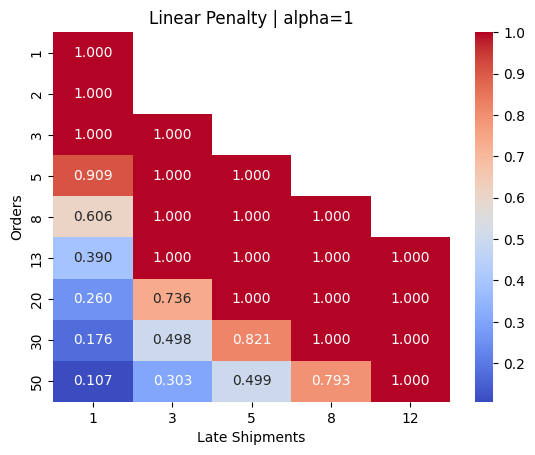

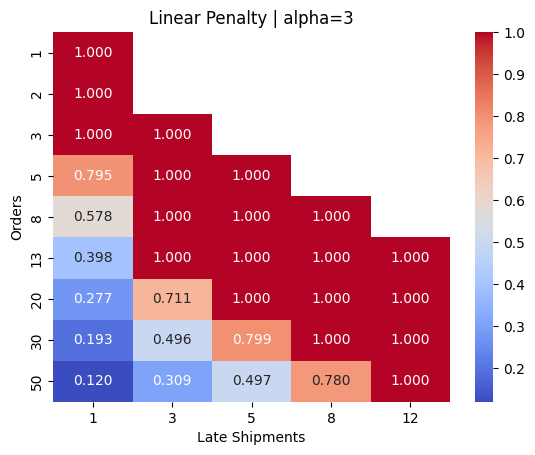

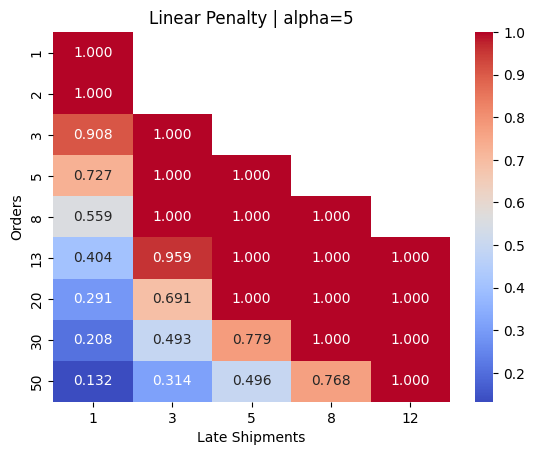

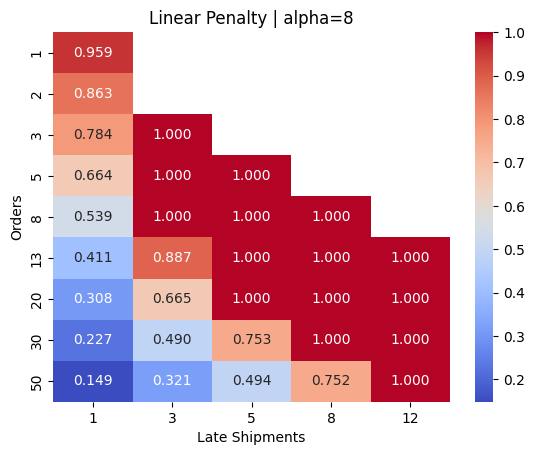

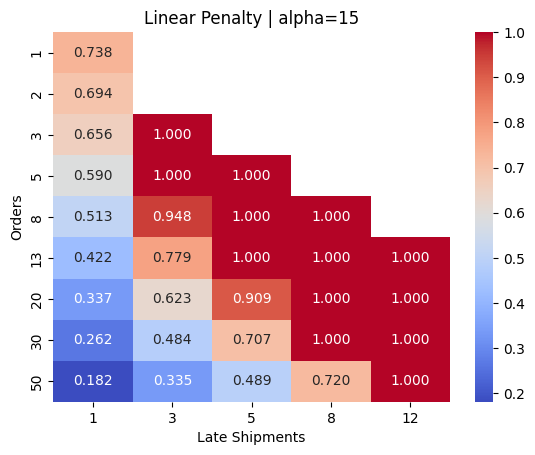

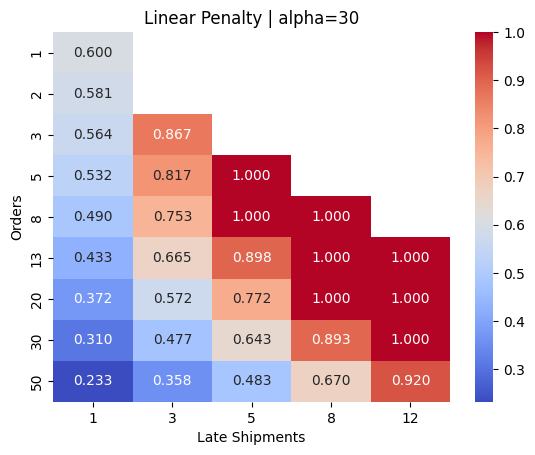

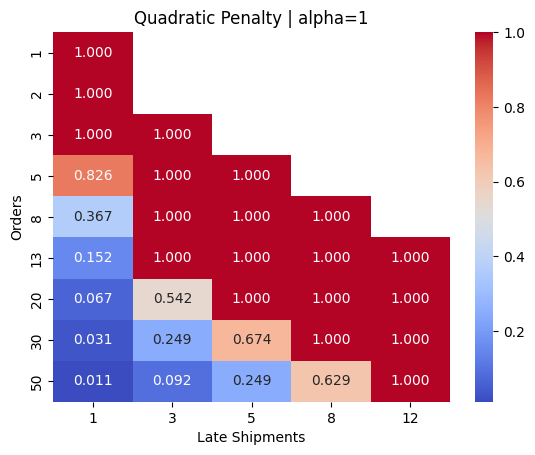

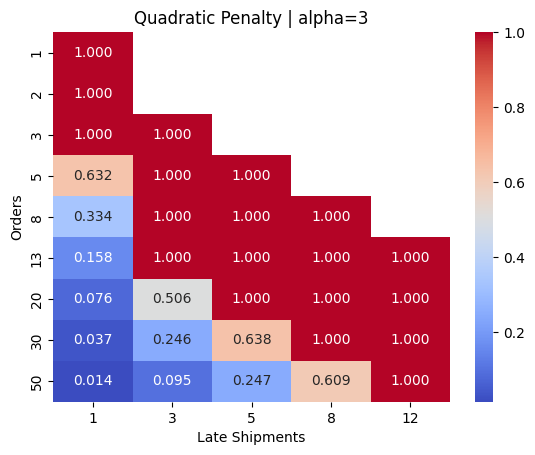

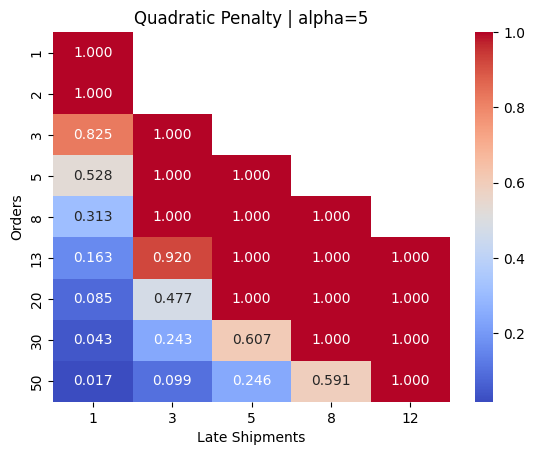

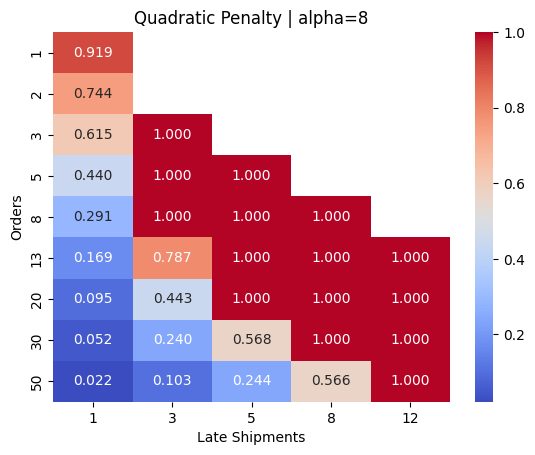

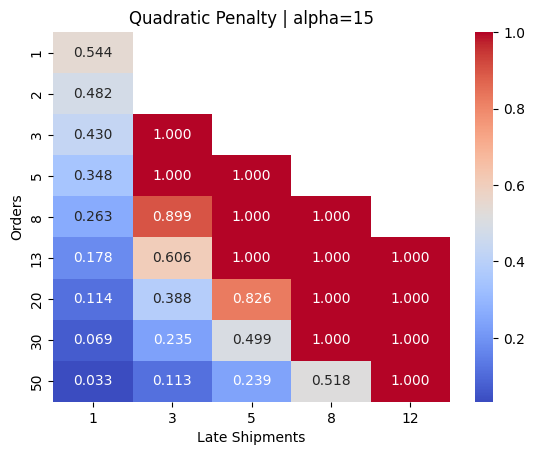

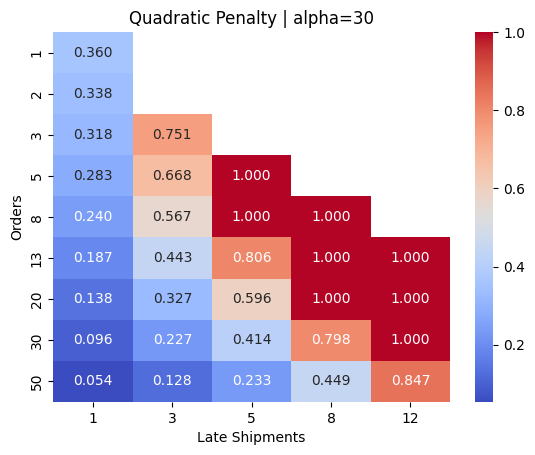

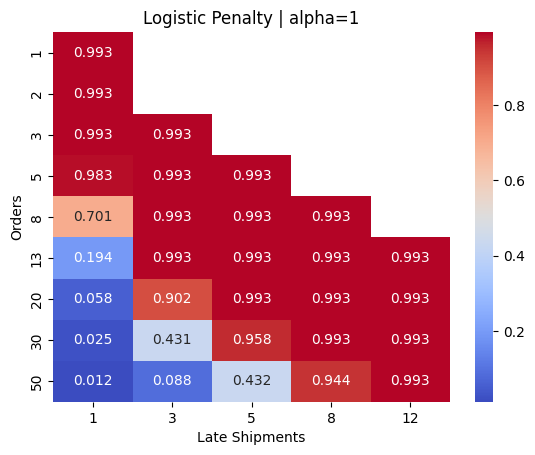

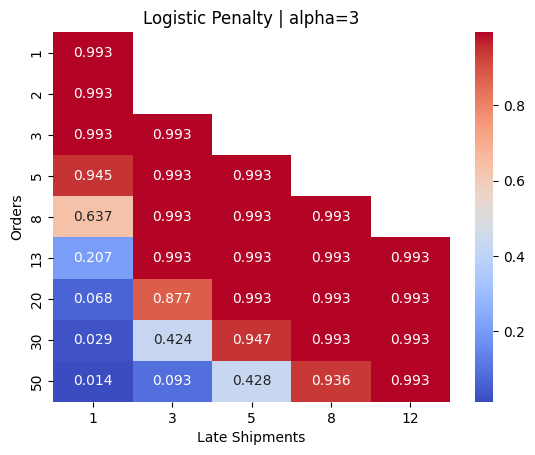

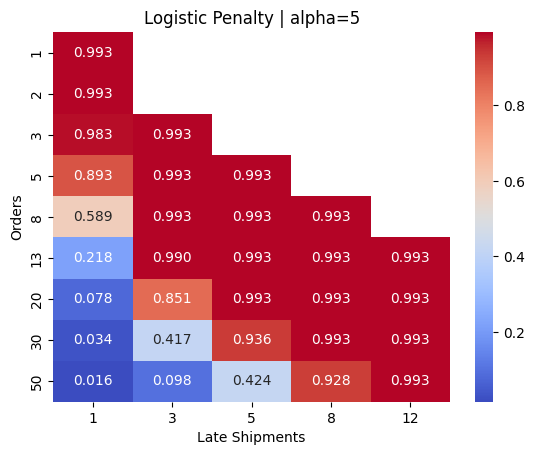

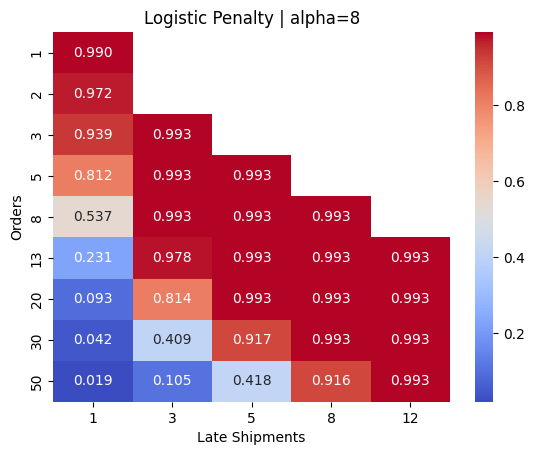

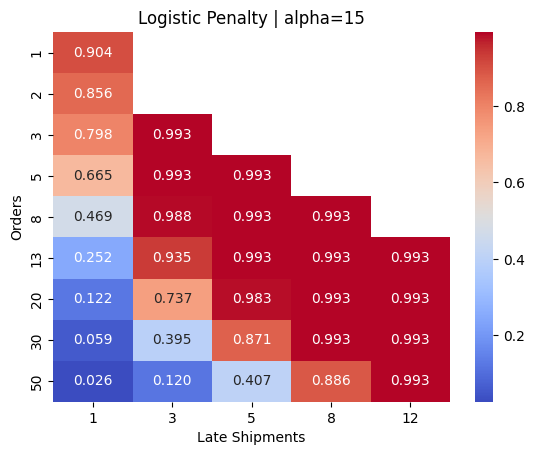

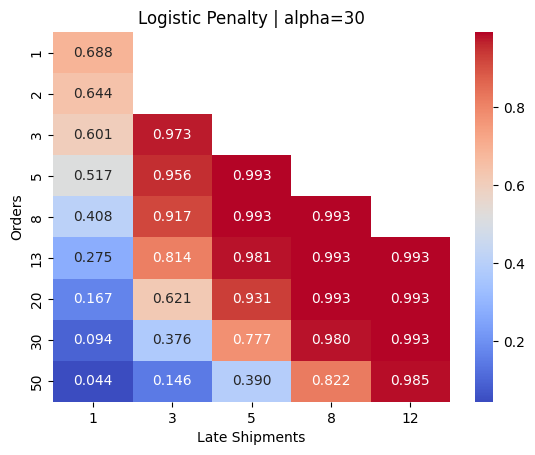

In [0]:
pdf = df_late.toPandas()

penalty_cols = {
    "Linear": "penalty_linear",
    "Quadratic": "penalty_quadratic",
    "Logistic": "penalty_logistic"
}

for name, col in penalty_cols.items():
    for a in alphas:
        subset = pdf[pdf["alpha"] == a]
        
        pivot = subset.pivot(
            index="orders",
            columns="late_shipments",
            values=col
        )
        
        plt.figure()
        sns.heatmap(
            pivot,
            annot=True,
            fmt=".3f",
            cmap="coolwarm"
        )
        
        plt.title(f"{name} Penalty | alpha={a}")
        plt.xlabel("Late Shipments")
        plt.ylabel("Orders")
        plt.show()

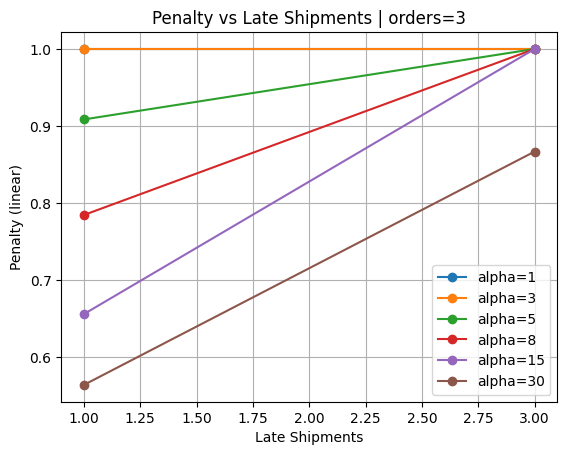

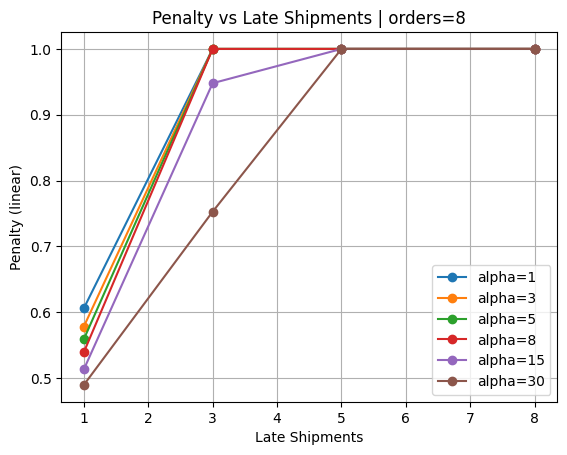

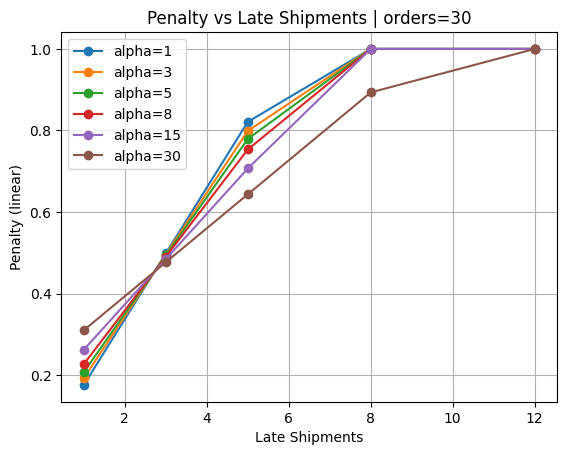

In [0]:
orders_focus = [3, 8, 30]

for o in orders_focus:
    subset = pdf[pdf["orders"] == o]
    
    plt.figure()
    
    for a in alphas:
        sub_a = subset[subset["alpha"] == a].sort_values("late_shipments")
        
        plt.plot(
            sub_a["late_shipments"],
            sub_a["penalty_linear"],   
            marker="o",
            label=f"alpha={a}"
        )

    
    plt.title(f"Penalty vs Late Shipments | orders={o}")
    plt.xlabel("Late Shipments")
    plt.ylabel("Penalty (linear)")
    plt.legend()
    plt.grid()
    plt.show()

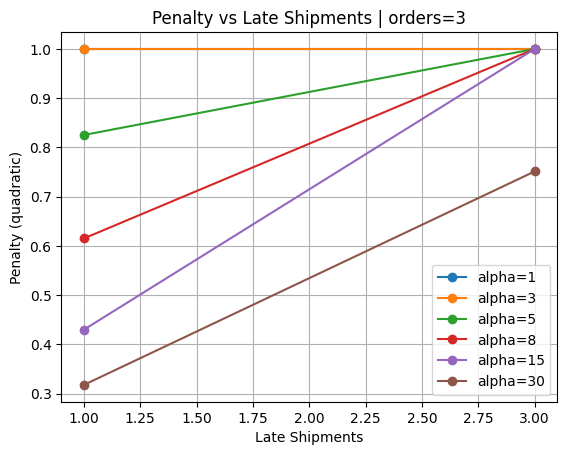

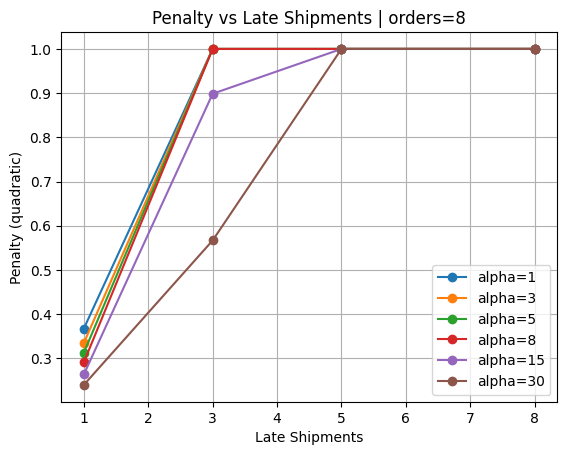

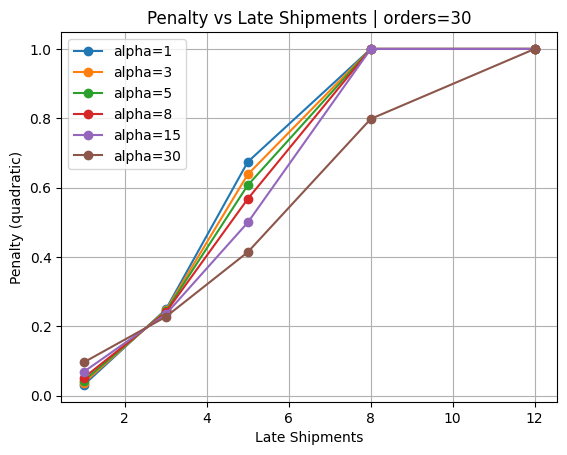

In [0]:
orders_focus = [3, 8, 30]

for o in orders_focus:
    subset = pdf[pdf["orders"] == o]
    
    plt.figure()
    
    for a in alphas:
        sub_a = subset[subset["alpha"] == a].sort_values("late_shipments")
        
        plt.plot(
            sub_a["late_shipments"],
            sub_a["penalty_quadratic"], 
            marker="o",
            label=f"alpha={a}"
        )

    
    plt.title(f"Penalty vs Late Shipments | orders={o}")
    plt.xlabel("Late Shipments")
    plt.ylabel("Penalty (quadratic)")
    plt.legend()
    plt.grid()
    plt.show()

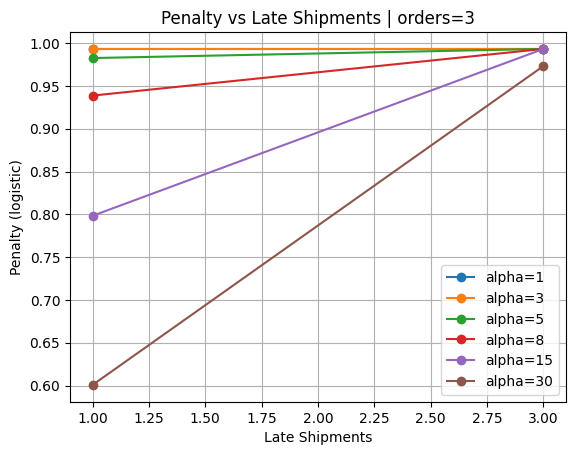

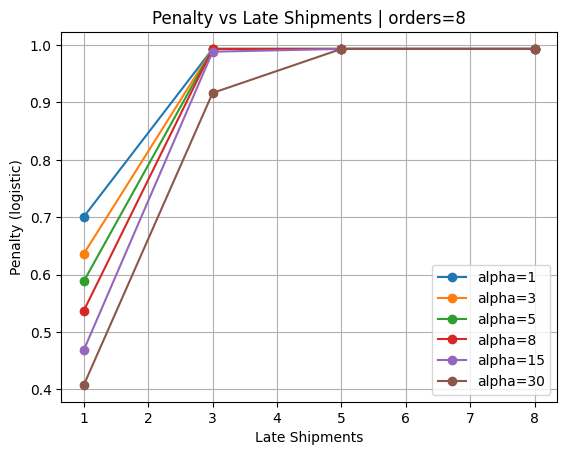

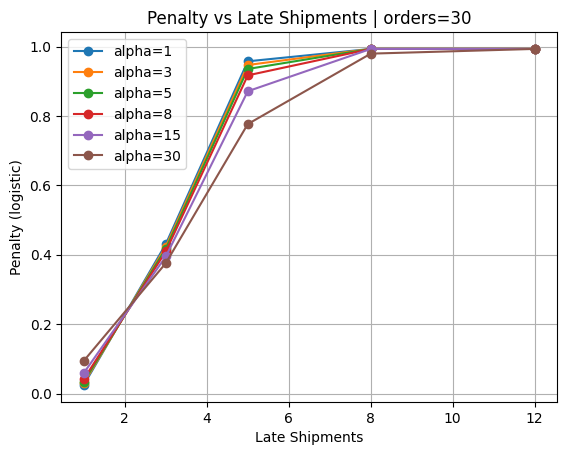

In [0]:
orders_focus = [3, 8, 30]

for o in orders_focus:
    subset = pdf[pdf["orders"] == o]
    
    plt.figure()
    
    for a in alphas:
        sub_a = subset[subset["alpha"] == a].sort_values("late_shipments")
        
        plt.plot(
            sub_a["late_shipments"],
            sub_a["penalty_logistic"], 
            marker="o",
            label=f"alpha={a}"
        )

    
    plt.title(f"Penalty vs Late Shipments | orders={o}")
    plt.xlabel("Late Shipments")
    plt.ylabel("Penalty (logistic)")
    plt.legend()
    plt.grid()
    plt.show()

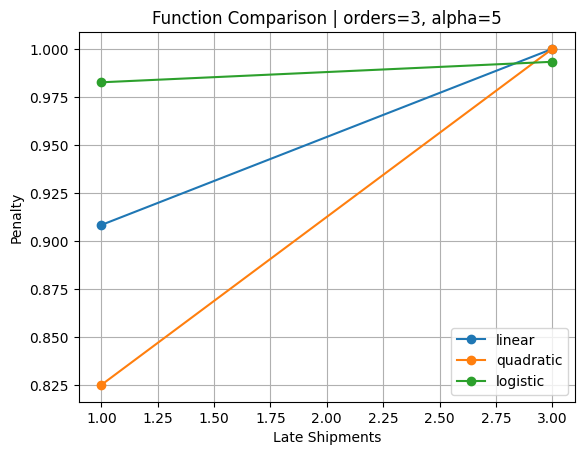

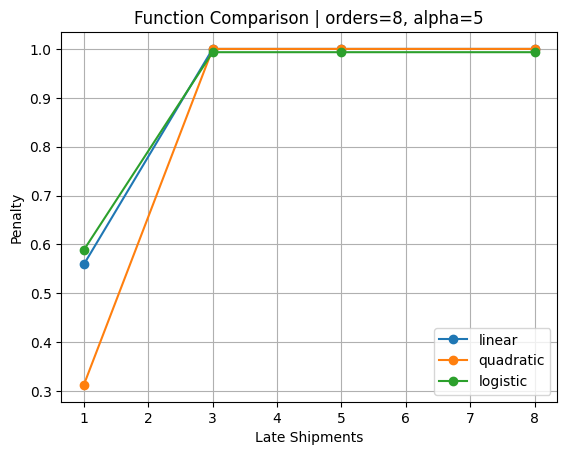

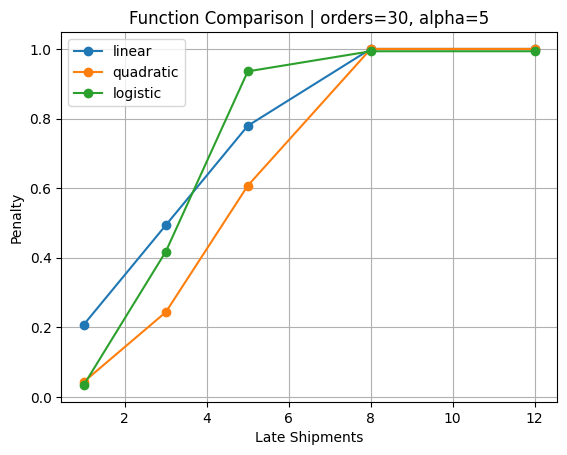

In [0]:
alpha_focus = 5
orders_focus = [3, 8, 30]

for o in orders_focus:
    subset = pdf[
        (pdf["orders"] == o) &
        (pdf["alpha"] == alpha_focus)
    ].sort_values("late_shipments")
    
    plt.figure()
    
    plt.plot(subset["late_shipments"], subset["penalty_linear"], marker="o", label="linear")
    plt.plot(subset["late_shipments"], subset["penalty_quadratic"], marker="o", label="quadratic")
    plt.plot(subset["late_shipments"], subset["penalty_logistic"], marker="o", label="logistic")
    
    plt.title(f"Function Comparison | orders={o}, alpha={alpha_focus}")
    plt.xlabel("Late Shipments")
    plt.ylabel("Penalty")
    plt.legend()
    plt.grid()
    plt.show()

### C) Claims

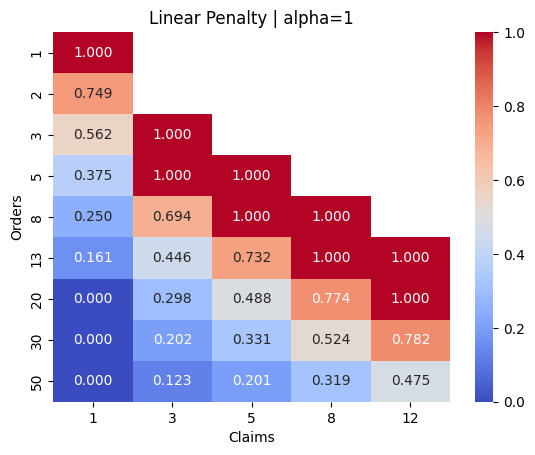

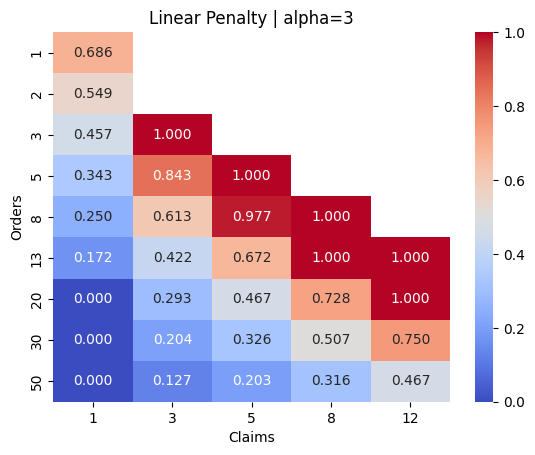

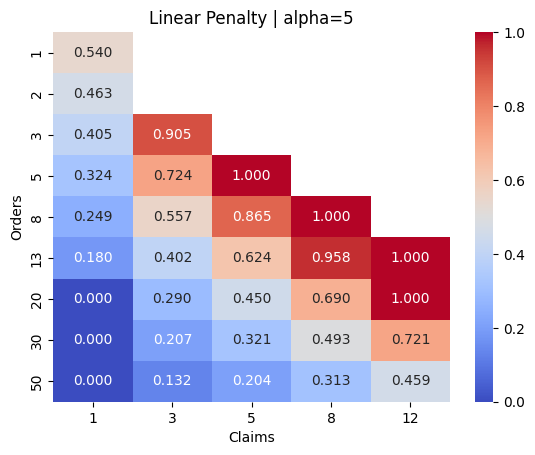

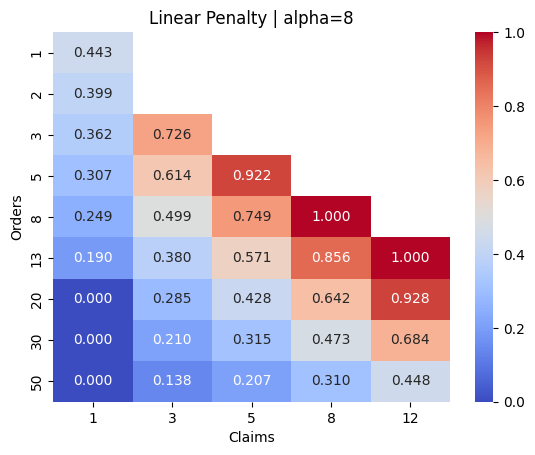

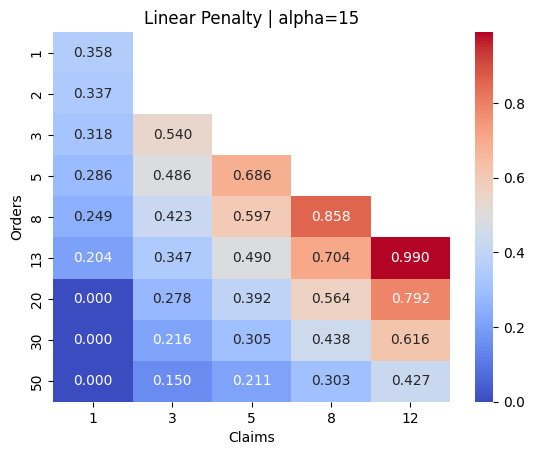

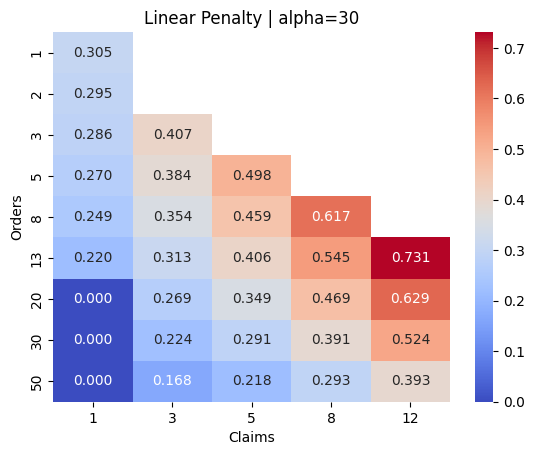

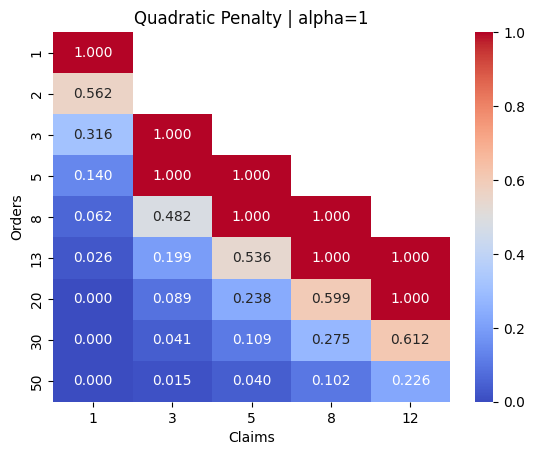

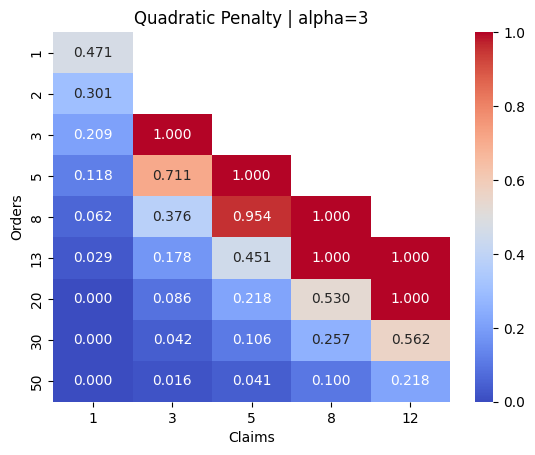

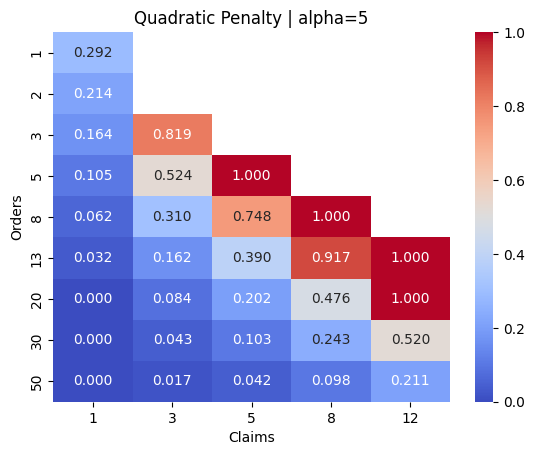

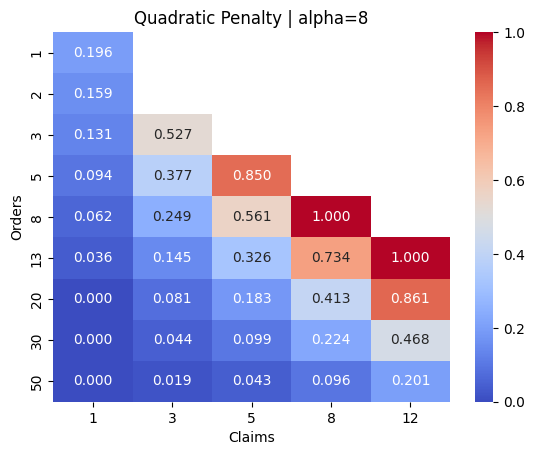

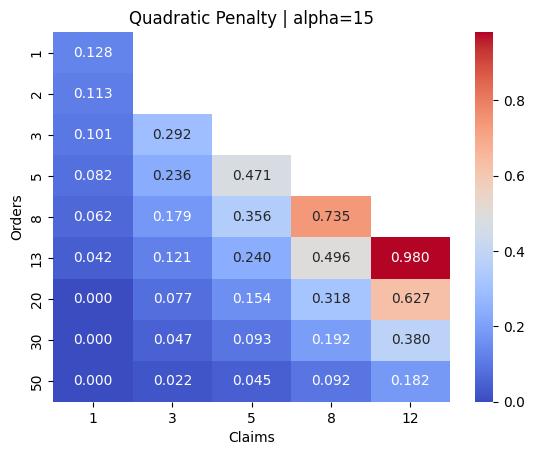

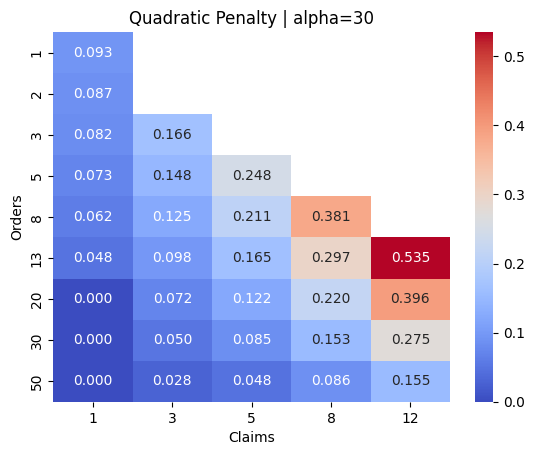

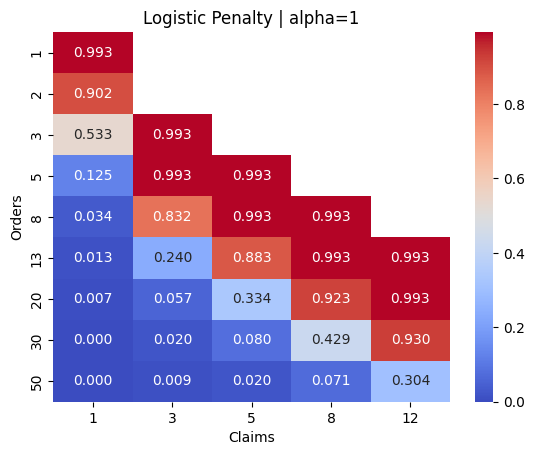

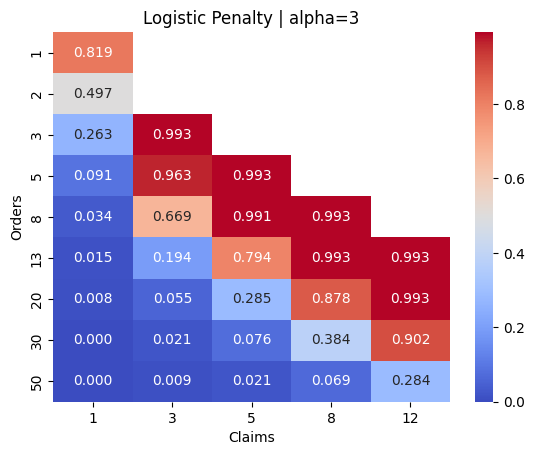

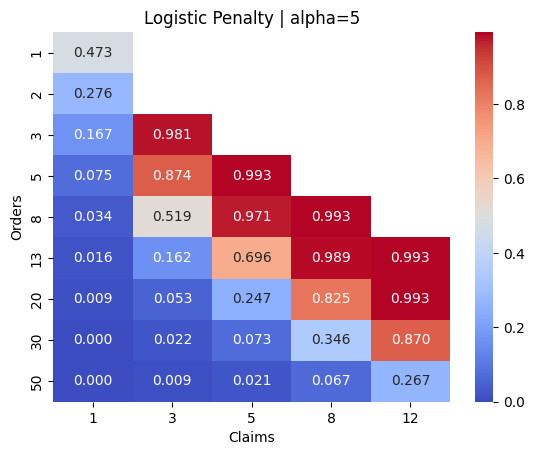

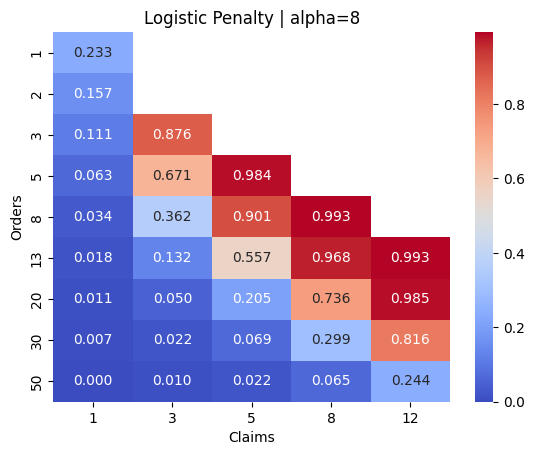

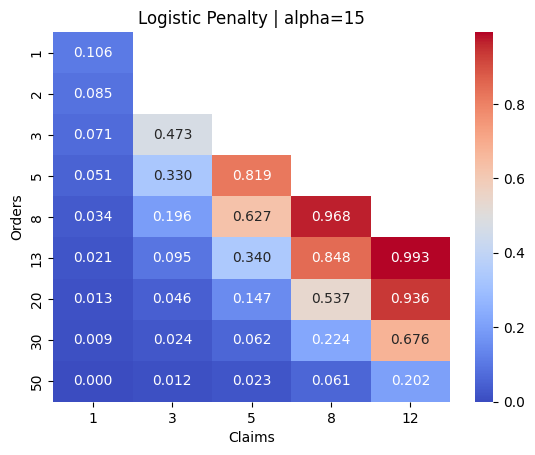

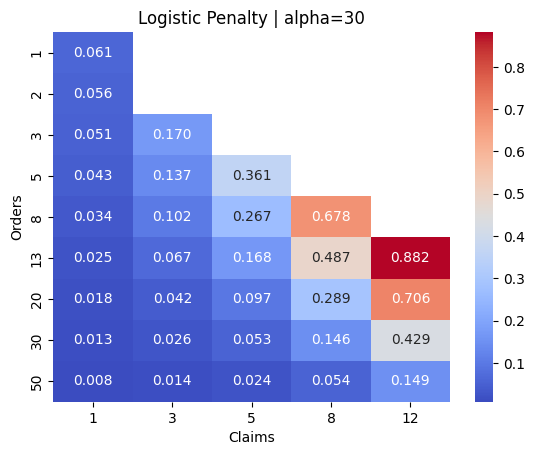

In [0]:
pdf = df_claims.toPandas()

penalty_cols = {
    "Linear": "penalty_linear",
    "Quadratic": "penalty_quadratic",
    "Logistic": "penalty_logistic"
}

for name, col in penalty_cols.items():
    for a in alphas:
        subset = pdf[pdf["alpha"] == a]
        
        pivot = subset.pivot(
            index="orders",
            columns="claims",
            values=col
        )
        
        plt.figure()
        sns.heatmap(
            pivot,
            annot=True,
            fmt=".3f",
            cmap="coolwarm"
        )
        
        plt.title(f"{name} Penalty | alpha={a}")
        plt.xlabel("Claims")
        plt.ylabel("Orders")
        plt.show()

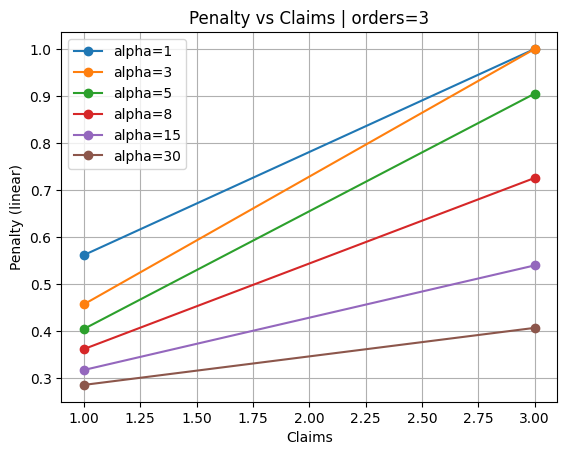

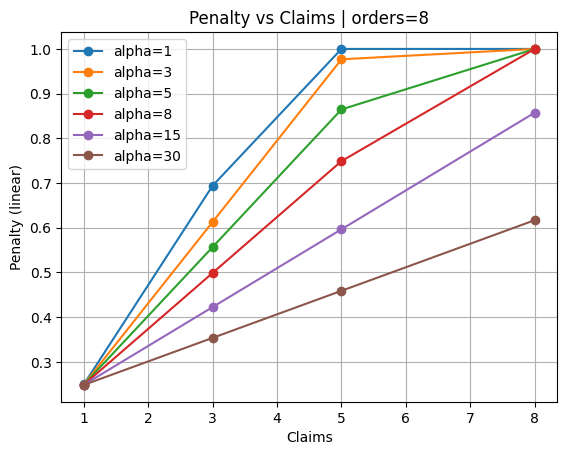

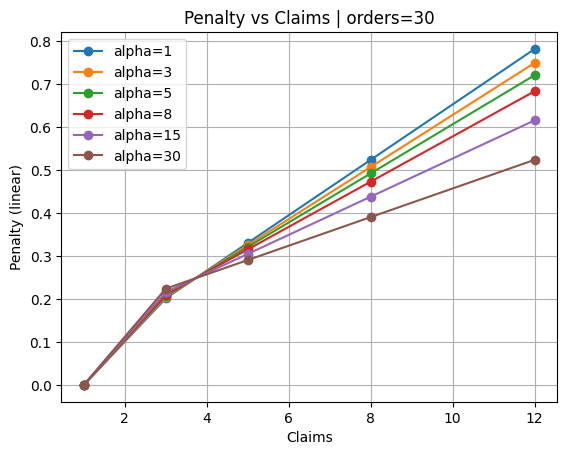

In [0]:
orders_focus = [3, 8, 30]

for o in orders_focus:
    subset = pdf[pdf["orders"] == o]
    
    plt.figure()
    
    for a in alphas:
        sub_a = subset[subset["alpha"] == a].sort_values("claims")
        
        plt.plot(
            sub_a["claims"],
            sub_a["penalty_linear"],   
            marker="o",
            label=f"alpha={a}"
        )

    
    plt.title(f"Penalty vs Claims | orders={o}")
    plt.xlabel("Claims")
    plt.ylabel("Penalty (linear)")
    plt.legend()
    plt.grid()
    plt.show()

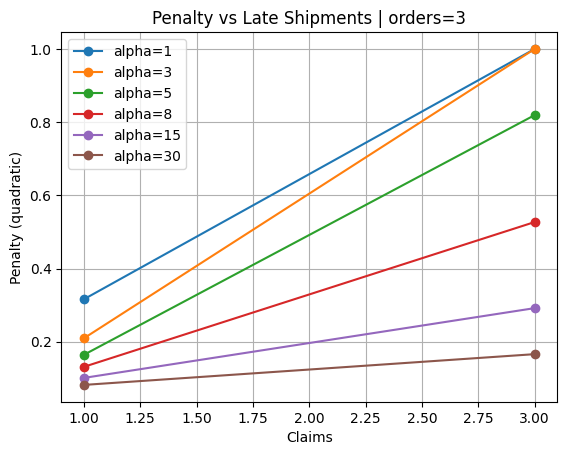

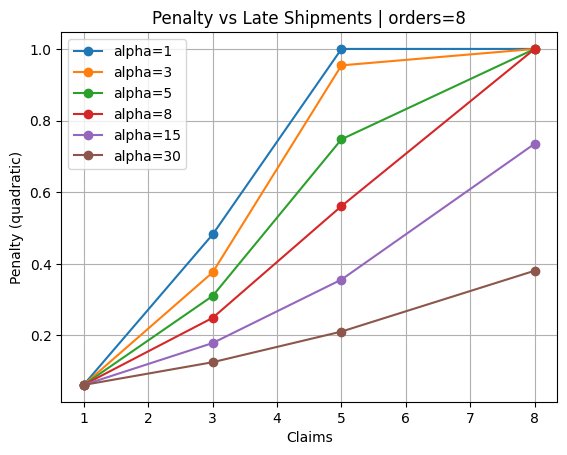

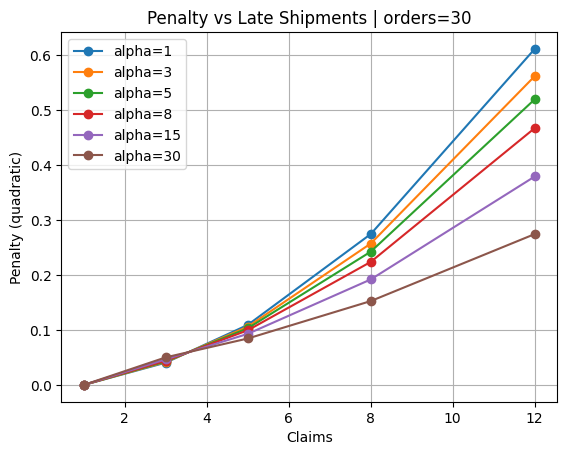

In [0]:
orders_focus = [3, 8, 30]

for o in orders_focus:
    subset = pdf[pdf["orders"] == o]
    
    plt.figure()
    
    for a in alphas:
        sub_a = subset[subset["alpha"] == a].sort_values("claims")
        
        plt.plot(
            sub_a["claims"],
            sub_a["penalty_quadratic"], 
            marker="o",
            label=f"alpha={a}"
        )

    
    plt.title(f"Penalty vs Late Shipments | orders={o}")
    plt.xlabel("Claims")
    plt.ylabel("Penalty (quadratic)")
    plt.legend()
    plt.grid()
    plt.show()

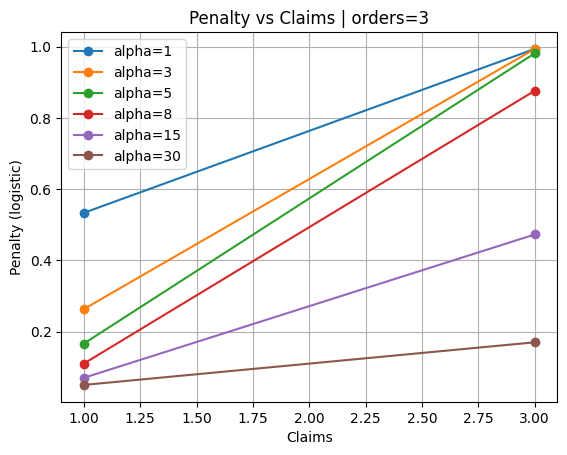

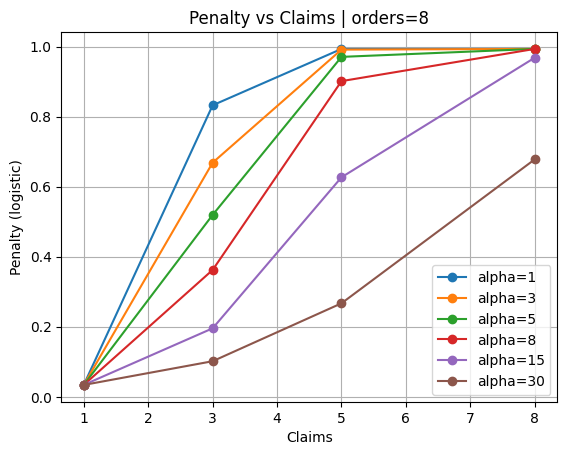

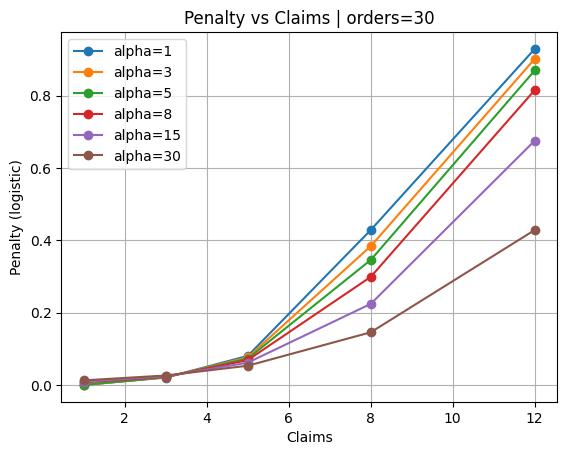

In [0]:
orders_focus = [3, 8, 30]

for o in orders_focus:
    subset = pdf[pdf["orders"] == o]
    
    plt.figure()
    
    for a in alphas:
        sub_a = subset[subset["alpha"] == a].sort_values("claims")
        
        plt.plot(
            sub_a["claims"],
            sub_a["penalty_logistic"], 
            marker="o",
            label=f"alpha={a}"
        )

    
    plt.title(f"Penalty vs Claims | orders={o}")
    plt.xlabel("Claims")
    plt.ylabel("Penalty (logistic)")
    plt.legend()
    plt.grid()
    plt.show()

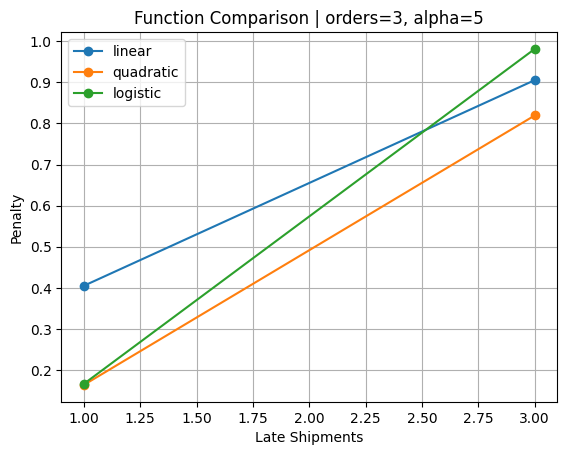

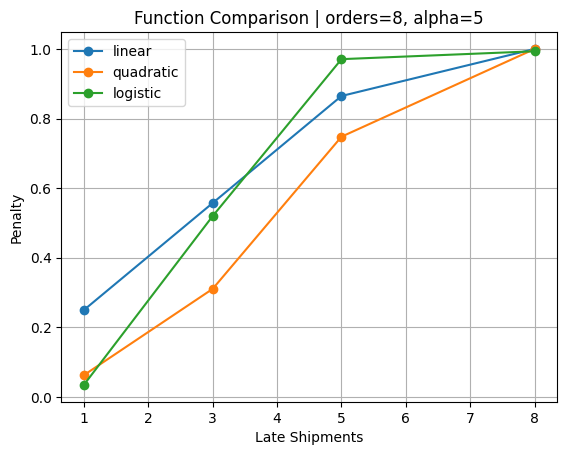

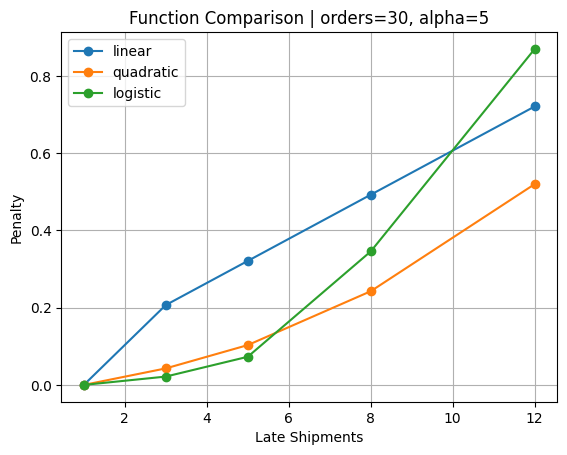

In [0]:
alpha_focus = 5
orders_focus = [3, 8, 30]

for o in orders_focus:
    subset = pdf[
        (pdf["orders"] == o) &
        (pdf["alpha"] == alpha_focus)
    ].sort_values("claims")
    
    plt.figure()
    
    plt.plot(subset["claims"], subset["penalty_linear"], marker="o", label="linear")
    plt.plot(subset["claims"], subset["penalty_quadratic"], marker="o", label="quadratic")
    plt.plot(subset["claims"], subset["penalty_logistic"], marker="o", label="logistic")
    
    plt.title(f"Function Comparison | orders={o}, alpha={alpha_focus}")
    plt.xlabel("Late Shipments")
    plt.ylabel("Penalty")
    plt.legend()
    plt.grid()
    plt.show()

# 5. Empirical Analysis - Applying penalties to real data

### 5.1 - Window Selection

The choice of time windows for aggregating orders and reviews is a key design decision, as it directly impacts the stability, responsiveness, and representativeness of the seller performance metrics.

- Short time windows tend to produce highly volatile metrics, especially for low-volume sellers (which are common in our database). In addition, low coverage leads to sparse data, unreliable if we want to make comparisons across sellers.

- Longer windows ensure that our computed ratios (e.g. late shipment rate, claims rate) are statistically meaningful and improves stability; but might reduce the model’s ability to reflect recent changes in seller behavior.

Based on the empirical analysis (see sections below), a **60 days window** is sellected both for orders and for reviews.

In [0]:

# Daily activity per seller (same orders and reviews as fact_seller_metrics)

df = create_daily_activity(dense_calendar, pit_orders, pit_reviews).withColumn(
    "ref_day",
    F.datediff(F.col("reference_date"), F.lit("1970-01-01"))
)

# 3 possible day windows are analyzed for orders. A higher window for reviews is considered, accounting for possible orders without review.

order_windows = [30, 60, 90]
review_multipliers = [1, 1.5]

results = df


for w in order_windows:
    
    order_window = Window.partitionBy("seller_key") \
        .orderBy("ref_day") \
        .rangeBetween(-(w + lag_days - 1), -lag_days)
    
    results = results.withColumn(
        f"orders_{w}d",
        F.sum(F.coalesce(F.col("orders"), F.lit(0))).over(order_window)
    )
    for m in review_multipliers:
        rw = int(w * m)
        
        review_window = Window.partitionBy("seller_key") \
            .orderBy("ref_day") \
            .rangeBetween(-(rw + lag_days - 1), -lag_days)
        
        results = results.withColumn(
            f"reviews_{rw}d",
            F.sum(F.coalesce(F.col("reviews_day"), F.lit(0))).over(review_window)
        )

# Filtering out rows without orders or reviews
results_filtered = results.filter(
    (F.col("orders_30d") > 0) | (F.col("reviews_60d") > 0)
)

In [0]:
display(results_filtered.selectExpr(
    "ROUND(AVG(orders_30d),2) as avg_orders_30d",
    "ROUND(AVG(orders_60d),2) as avg_orders_60d",
    "ROUND(AVG(orders_90d),2) as avg_orders_90d",
    "PERCENTILE(orders_30d, 0.5) as median_orders_30d",
    "PERCENTILE(orders_60d, 0.5) as median_orders_60d",
    "PERCENTILE(orders_90d, 0.5) as median_orders_90d"
))

avg_orders_30d,avg_orders_60d,avg_orders_90d,median_orders_30d,median_orders_60d,median_orders_90d
4.6,8.84,12.74,1.0,3.0,4.0


In [0]:
display(results_filtered.selectExpr(
    "ROUND(AVG(reviews_30d),2) AS avg_reviews_30d",
    "ROUND(AVG(reviews_45d),2) AS avg_reviews_45d",
    "ROUND(AVG(reviews_60d),2) AS avg_reviews_60d",
    "ROUND(AVG(reviews_90d),2) AS avg_reviews_90d",
    "ROUND(AVG(reviews_135d),2) AS avg_reviews_135d",
    "ROUND(PERCENTILE(reviews_30d, 0.5),2) AS median_reviews_30d",
    "ROUND(PERCENTILE(reviews_45d, 0.5),2) AS median_reviews_45d",
    "ROUND(PERCENTILE(reviews_60d, 0.5),2) AS median_reviews_60d",
    "ROUND(PERCENTILE(reviews_90d, 0.5),2) AS median_reviews_90d",
    "ROUND(PERCENTILE(reviews_135d, 0.5),2) AS median_reviews_135d"
))

avg_reviews_30d,avg_reviews_45d,avg_reviews_60d,avg_reviews_90d,avg_reviews_135d,median_reviews_30d,median_reviews_45d,median_reviews_60d,median_reviews_90d,median_reviews_135d
4.21,6.18,8.1,11.56,16.09,1.0,2.0,3.0,4.0,5.0


The distributions of orders and reviews are very similar, specially when the windows of 60 days or more. For 60 days window we have comparable averages (~8.8 orders vs ~8.1 reviews) and identical medians (3)

This indicates that, in this dataset, most orders have an associated review, and there is no significant lag between order activity and review generation.

In [0]:
display(results_filtered.selectExpr(
    "COUNT(*) as total",
    
    "ROUND(SUM(CASE WHEN orders_30d >= 3 THEN 1 ELSE 0 END)/COUNT(*),2) AS pct_30d_3",
    "ROUND(SUM(CASE WHEN orders_60d >= 3 THEN 1 ELSE 0 END)/COUNT(*),2) AS pct_60d_3",
    "ROUND(SUM(CASE WHEN orders_90d >= 3 THEN 1 ELSE 0 END)/COUNT(*),2) AS pct_90d_3",
    
    "ROUND(SUM(CASE WHEN orders_30d >= 5 THEN 1 ELSE 0 END)/COUNT(*),2) AS pct_30d_5",
    "ROUND(SUM(CASE WHEN orders_60d >= 5 THEN 1 ELSE 0 END)/COUNT(*),2) AS pct_60d_5",
    "ROUND(SUM(CASE WHEN orders_90d >= 5 THEN 1 ELSE 0 END)/COUNT(*),2) AS pct_90d_5"
))

total,pct_30d_3,pct_60d_3,pct_90d_3,pct_30d_5,pct_60d_5,pct_90d_5
639378,0.37,0.54,0.64,0.23,0.38,0.47


In [0]:
display(results_filtered.selectExpr(
    "COUNT(*) as total",
    
    "ROUND(SUM(CASE WHEN reviews_30d >= 3 THEN 1 ELSE 0 END)/COUNT(*),2) AS pct_30d_3",
    "ROUND(SUM(CASE WHEN reviews_60d >= 3 THEN 1 ELSE 0 END)/COUNT(*),2) AS pct_60d_3",
    "ROUND(SUM(CASE WHEN reviews_90d >= 3 THEN 1 ELSE 0 END)/COUNT(*),2) AS pct_90d_3",
    
    "ROUND(SUM(CASE WHEN reviews_30d >= 5 THEN 1 ELSE 0 END)/COUNT(*),2) AS pct_30d_5",
    "ROUND(SUM(CASE WHEN reviews_60d >= 5 THEN 1 ELSE 0 END)/COUNT(*),2) AS pct_60d_5",
    "ROUND(SUM(CASE WHEN reviews_90d >= 5 THEN 1 ELSE 0 END)/COUNT(*),2) AS pct_90d_5"
))

total,pct_30d_3,pct_60d_3,pct_90d_3,pct_30d_5,pct_60d_5,pct_90d_5
639378,0.34,0.51,0.6,0.22,0.35,0.44


Coverage improves significantly when increasing the window from 30 to 60 days. The proportion of sellers with at least 3 orders increases from ~37% (30d) to ~54% (60d).

Further increases to 90 days provide diminishing returns while reducing responsiveness.

In [0]:
display(results_filtered.selectExpr(
    "percentile(orders_30d, array(0.25, 0.5, 0.75, 0.9)) ",
    "percentile(orders_60d, array(0.25, 0.5, 0.75, 0.9)) ",
    "percentile(orders_90d, array(0.25, 0.5, 0.75, 0.9)) ",
    "percentile(reviews_30d, array(0.25, 0.5, 0.75, 0.9)) ",
    "percentile(reviews_60d, array(0.25, 0.5, 0.75, 0.9)) ",
    "percentile(reviews_90d, array(0.25, 0.5, 0.75, 0.9)) ",
))



"percentile(orders_30d, array(0.25, 0.5, 0.75, 0.9), 1)","percentile(orders_60d, array(0.25, 0.5, 0.75, 0.9), 1)","percentile(orders_90d, array(0.25, 0.5, 0.75, 0.9), 1)","percentile(reviews_30d, array(0.25, 0.5, 0.75, 0.9), 1)","percentile(reviews_60d, array(0.25, 0.5, 0.75, 0.9), 1)","percentile(reviews_90d, array(0.25, 0.5, 0.75, 0.9), 1)"
"List(1.0, 1.0, 4.0, 10.0)","List(1.0, 3.0, 8.0, 20.0)","List(2.0, 4.0, 11.0, 28.0)","List(0.0, 1.0, 4.0, 10.0)","List(1.0, 3.0, 7.0, 18.0)","List(1.0, 4.0, 10.0, 26.0)"



The distribution of orders is highly skewed (long-tail). This reinforces the need for a window that captures sufficient activity for the majority of sellers without over-smoothing.



Based on the empirical analysis, a **60-day window** is selected for both orders and reviews since it:
- Provides a good balance between stability and responsiveness
- Achieves sufficient coverage for a majority of sellers
- Avoids unnecessary lag introduced by longer windows (e.g., 90 days)
- Ensures consistency across metrics, simplifying the interpretation of the model

Using said reference window, ratios regarding the three relevant metrics (late shipments and claims) are computed. The results are `fact_seller_metrics`table, within the gold layer of the medallion architecture of the project.

#### Raw reference metrics

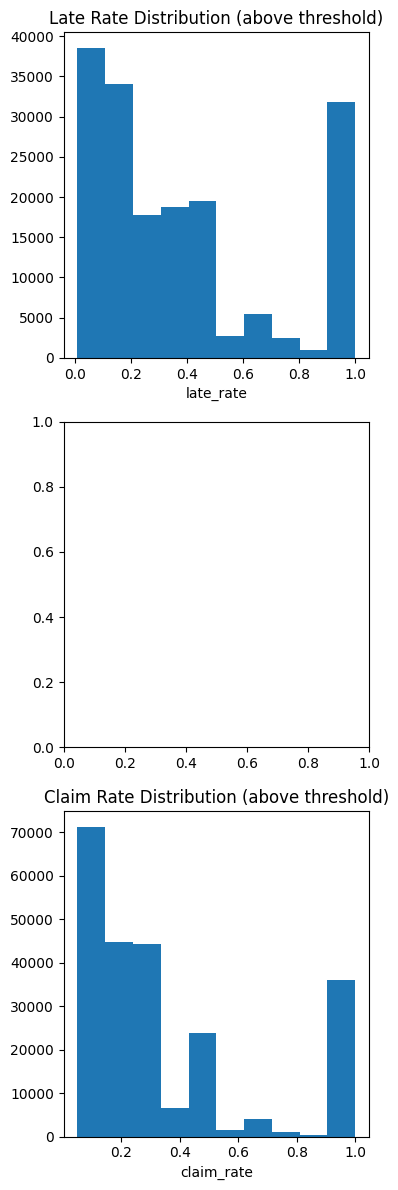

In [0]:
late_pdf = (
    fact_seller_metrics
    .filter(fact_seller_metrics.late_rate > late_th)
    .select("late_rate")
    .toPandas()
)


claim_pdf = (
    fact_seller_metrics
    .filter(fact_seller_metrics.claim_rate > claim_th)
    .select("claim_rate")
    .toPandas()
)

fig, axes = plt.subplots(3, 1, figsize=(4, 12))

# Late histogram
axes[0].hist(late_pdf["late_rate"], bins=10)
axes[0].set_title("Late Rate Distribution (above threshold)")
axes[0].set_xlabel("late_rate")


# Claim histogram
axes[2].hist(claim_pdf["claim_rate"], bins=10)
axes[2].set_title("Claim Rate Distribution (above threshold)")
axes[2].set_xlabel("claim_rate")

plt.tight_layout()
plt.show()

### 5.2 - Evolution of orders and reviews

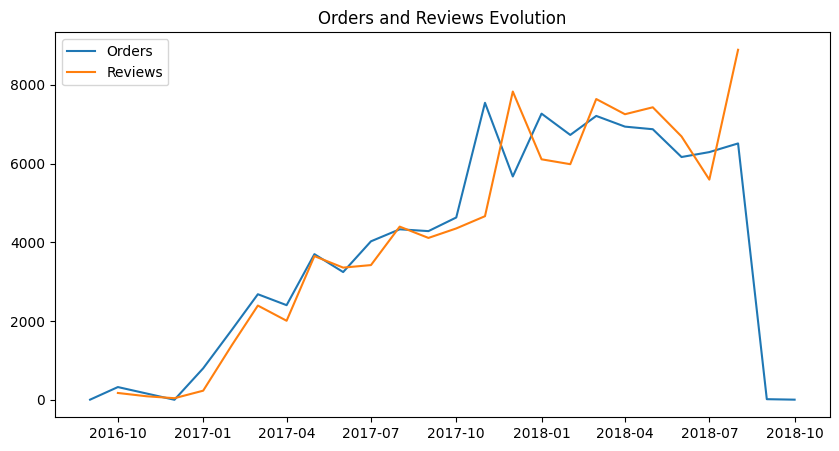

In [0]:
# Orders by month
orders_ts = (
    fact_orders
    .withColumn("month", F.date_trunc("month", "order_purchase_ts"))
    .groupBy("month")
    .agg(F.countDistinct("order_id").alias("orders"))
)

reviews_ts = (
    fact_reviews
    .withColumn("month", F.date_trunc("month", "review_creation_date"))
    .groupBy("month")
    .agg(F.countDistinct("review_id").alias("reviews"))
)

# Plot

orders_pd = orders_ts.toPandas().sort_values(["month", "orders"])
reviews_pd = reviews_ts.toPandas().sort_values(["month", "reviews"])

plt.figure(figsize=(10,5))
plt.plot(orders_pd["month"], orders_pd["orders"], label="Orders")
plt.plot(reviews_pd["month"], reviews_pd["reviews"], label="Reviews")
plt.legend()
plt.title("Orders and Reviews Evolution")
plt.show()

In [0]:
reviews_lag = (
    fact_reviews.alias("r")
    .join(
        fact_orders.select("order_id", "order_purchase_ts").alias("o"),
        on="order_id",
        how="inner"
    )
    .withColumn(
        "review_lag_days",
        F.datediff(
            F.col("r.review_creation_date"),
            F.col("o.order_purchase_ts")
        )
    )
)

avg_review_lag = (
    reviews_lag
    .agg(
        F.avg("review_lag_days").alias("avg_review_lag_days")
    )
    .collect()[0]["avg_review_lag_days"]
)

print(f"Average review lag: {avg_review_lag:.2f} days")

Average review lag: 13.18 days


Both orders and reviews show a very similar evolution over time, suggesting that customer review activity scales consistently with platform transaction volume.

Additionally, the average lag between order purchase and review creation is approximately 13 days, which is consistent with the expected delivery and post-purchase feedback cycle. 


#### Number of Elegible sellers

*Eligible sellers* are sellers with at least one relevant activity event — either an order or a review — occurring between 61 and 2 days prior to the reference date. Only these sellers can receive valid reference metrics and therefore be assigned a seller index.

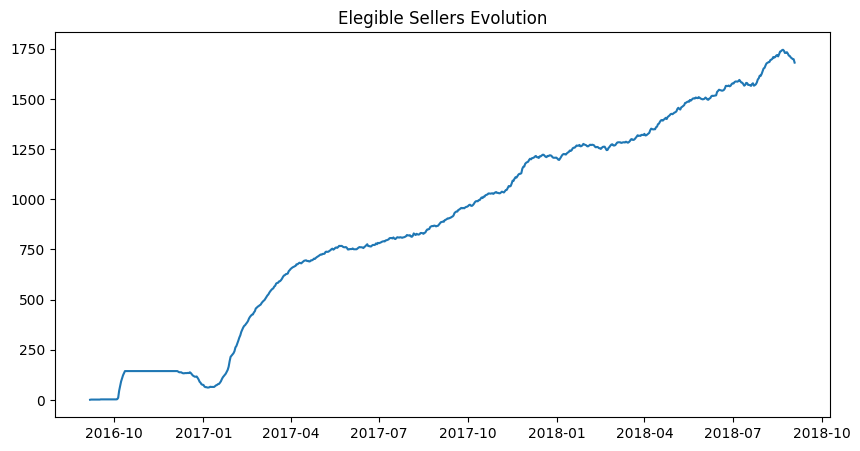

In [0]:
sellers_ts = (
    fact_seller_metrics
    .groupBy("reference_date")
    .agg(F.countDistinct("seller_key").alias("n_sellers"))
)

sellers_pd = sellers_ts.toPandas().sort_values(["reference_date"])

plt.figure(figsize=(10,5))
plt.plot(sellers_pd["reference_date"], sellers_pd["n_sellers"])
plt.title("Elegible Sellers Evolution")
plt.show()

#### Orders per seller

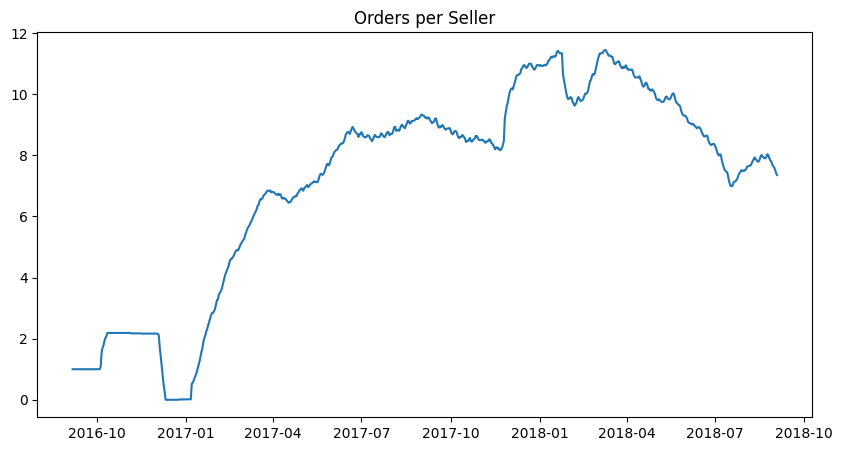

In [0]:
orders_per_seller = (
    fact_seller_metrics
    .groupBy("reference_date")
    .agg(
        (F.sum(f"orders_{window_days}d") / F.countDistinct("seller_key")).alias("orders_per_seller")
    )
)

ops_pd = orders_per_seller.toPandas().sort_values(["reference_date"])

plt.figure(figsize=(10,5))
plt.plot(ops_pd["reference_date"], ops_pd["orders_per_seller"])
plt.title("Orders per Seller")
plt.show()

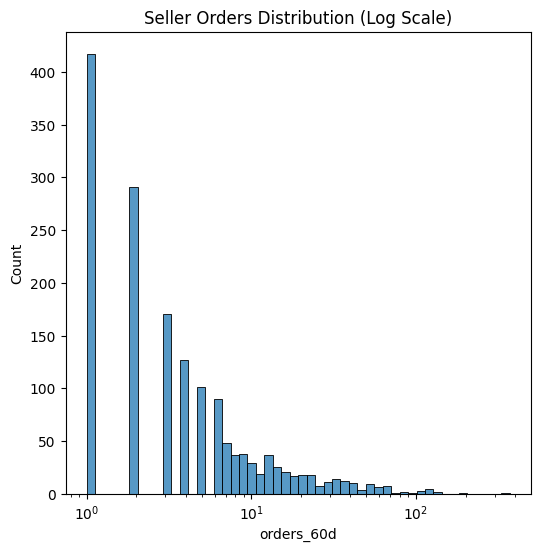

In [0]:
dist_df = (
    fact_seller_metrics
    .filter(F.col("reference_date") == fact_seller_metrics.agg(F.max("reference_date")).first()[0])
    .select(f"orders_{window_days}d")
)

dist_pd = dist_df.toPandas()

plt.figure(figsize=(6,6))
sns.histplot(dist_pd[f"orders_{window_days}d"], bins=50, log_scale=True)
plt.title("Seller Orders Distribution (Log Scale)")
plt.show()

## 5.3 - Seller index Construction

#### Bayesian Smoothing

In [0]:
seller_index = apply_bayesian_smoothing(fact_seller_metrics, config_params, window_days)

#### Threshold and Cap

In [0]:
# Evaluation vs threshold

# Excess ratio and cap

seller_index = apply_threshold_and_cap(seller_index, config_params)

seller_index = (
    seller_index
    .withColumn(
        "late_rate_capped",
        (F.col("ratio_late_capped") * late_th)
    )
    .withColumn(
        "claim_rate_capped",
        (F.col("ratio_claim_capped") * claim_th)
    )
)


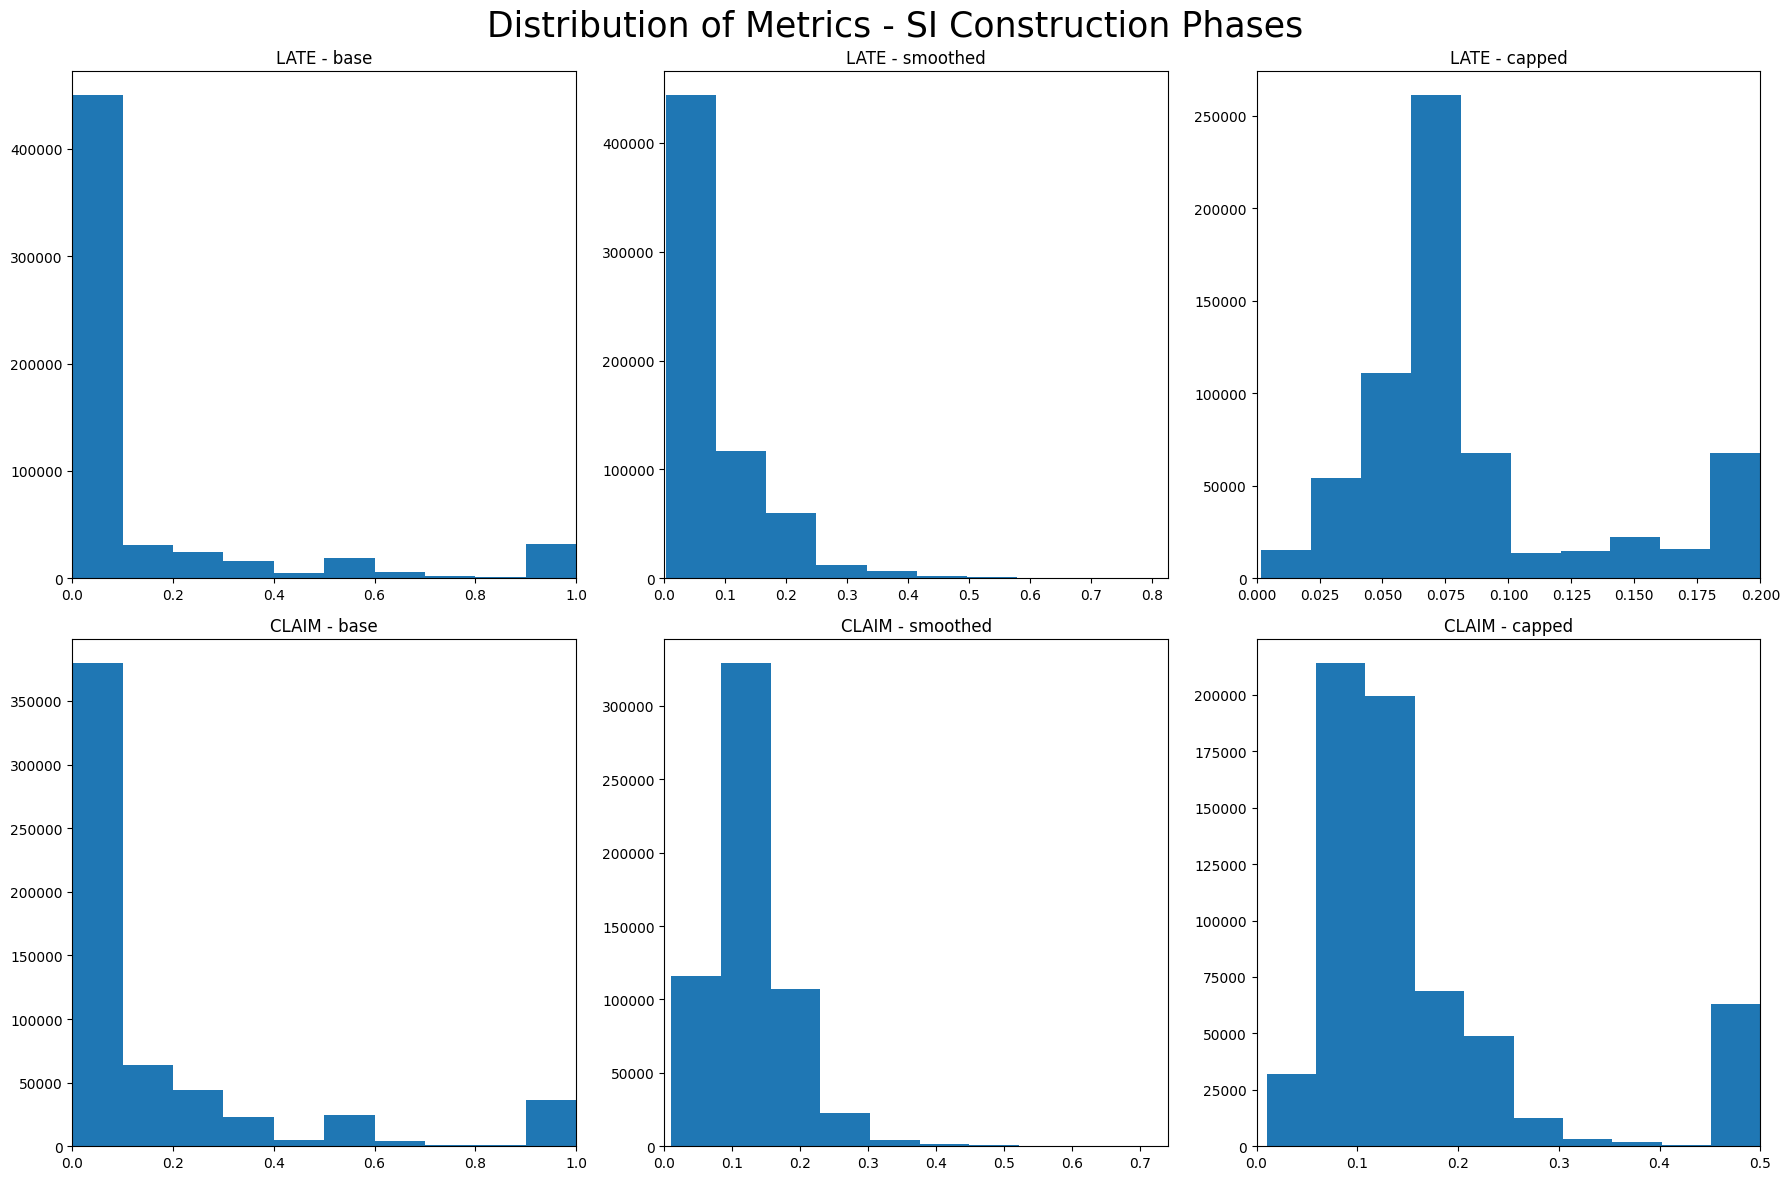

In [0]:

pdf_late = seller_index.select(
    "late_rate",
    "late_rate_smoothed",
    "late_rate_capped"
).toPandas()

pdf_claim = seller_index.select(
    "claim_rate",
    "claim_rate_smoothed",
    "claim_rate_capped"
).toPandas()

# Map

pdf_map = {
    "late": pdf_late,
    "claim": pdf_claim
}

# Histogram structure

metrics = ["late", "claim"]
versions = ["base", "smoothed", "capped"]

fig, axes = plt.subplots(len(metrics), len(versions), figsize=(18, 12))

fig.suptitle(
    "Distribution of Metrics - SI Construction Phases",
    fontsize=25
)

for i, metric in enumerate(metrics):

    pdf = pdf_map[metric]

    col_map = {
        "base": f"{metric}_rate",
        "smoothed": f"{metric}_rate_smoothed",
        "capped": f"{metric}_rate_capped"
    }

    for j, version in enumerate(versions):

        col_name = col_map[version]

        ax = axes[i, j]

        ax.hist(pdf[col_name].dropna(), bins=10)

        ax.set_title(f"{metric.upper()} - {version}")

        # Axis consistency
        ax.set_xlim(0, pdf[col_name].max())


plt.tight_layout()
plt.show()

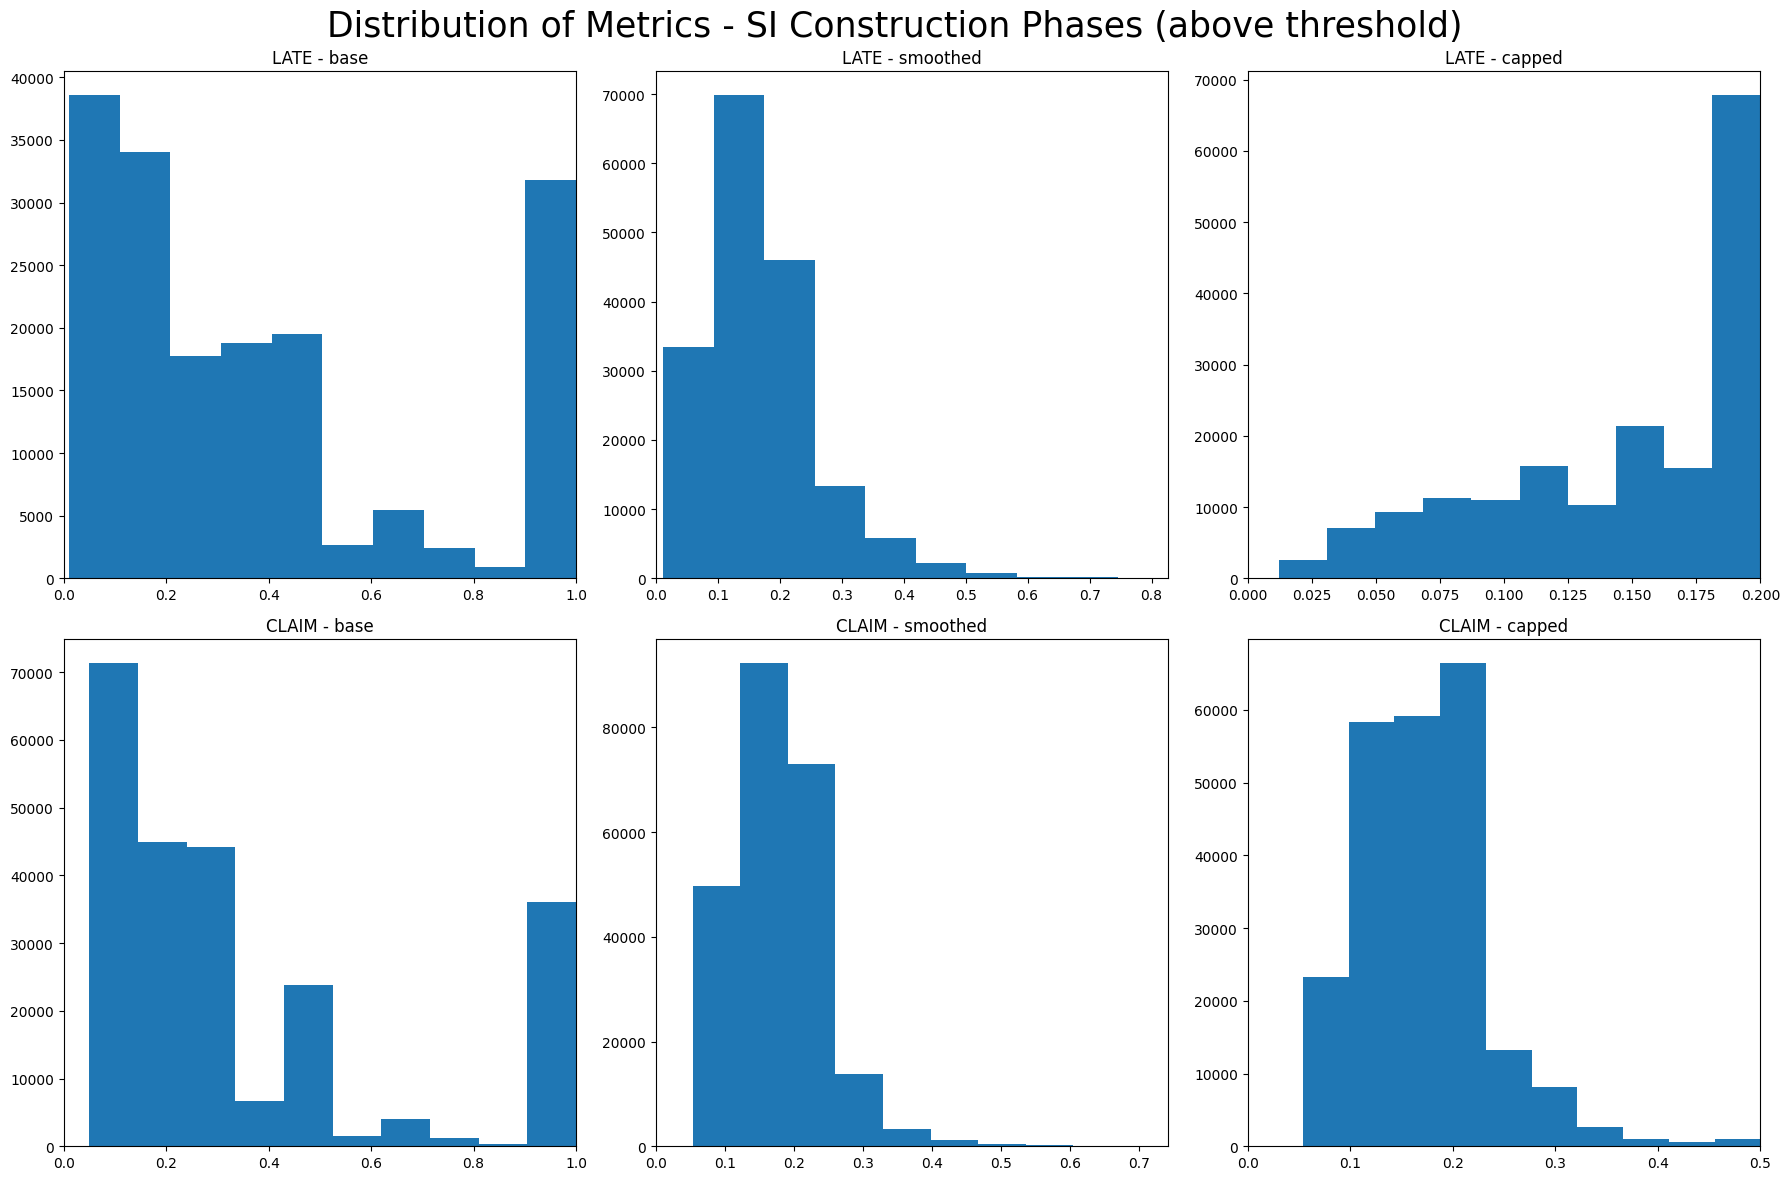

In [0]:

seller_index_capped = (
    seller_index
    .withColumn(
        "late_rate_capped",
        (F.col("ratio_late_capped") * late_th)
    )
    .withColumn(
        "claim_rate_capped",
        (F.col("ratio_claim_capped") * claim_th)
    )
)


pdf_late = (
    seller_index
    .filter(F.col("late_rate") > late_th)
    .select(
        "late_rate",
        "late_rate_smoothed",
        "late_rate_capped"
    )
    .toPandas()
)


pdf_claim = (
    seller_index
    .filter(F.col("claim_rate") > claim_th)
    .select(
        "claim_rate",
        "claim_rate_smoothed",
        "claim_rate_capped"
    )
    .toPandas()
)

# Map

pdf_map = {
    "late": pdf_late,
    "claim": pdf_claim
}

# Histogram structure

metrics = ["late", "claim"]
versions = ["base", "smoothed", "capped"]

fig, axes = plt.subplots(len(metrics), len(versions), figsize=(18, 12))

fig.suptitle(
    "Distribution of Metrics - SI Construction Phases (above threshold)",
    fontsize=25
)


for i, metric in enumerate(metrics):

    pdf = pdf_map[metric]

    col_map = {
        "base": f"{metric}_rate",
        "smoothed": f"{metric}_rate_smoothed",
        "capped": f"{metric}_rate_capped"
    }

    for j, version in enumerate(versions):

        col_name = col_map[version]

        ax = axes[i, j]

        ax.hist(pdf[col_name].dropna(), bins=10)

        ax.set_title(f"{metric.upper()} - {version}")

        # Axis consistency
        ax.set_xlim(0, pdf[col_name].max())

plt.tight_layout()
plt.show()

With the production parameters, around 29% of seller-days have a raw late rate above the 1% threshold (40% for claims above 5%), and almost half of them (44%) belong to sellers with 5 or fewer shipments in the window. The smoothing pulls these extreme values towards the marketplace average: the median late rate of the seller-days above the threshold goes from 26% to 16%, and the share of seller-days with a late rate of 50% or more drops from 35% to less than 1%.

The cap is relevant mainly for late shipments: about one in five seller-days above the threshold reaches the 20x cap, while the claims cap (10x) is almost never reached.

### Penalty alternatives

In [0]:
# Linear, quadratic and logistic penalties

seller_index = calculate_penalties(seller_index, config_params)

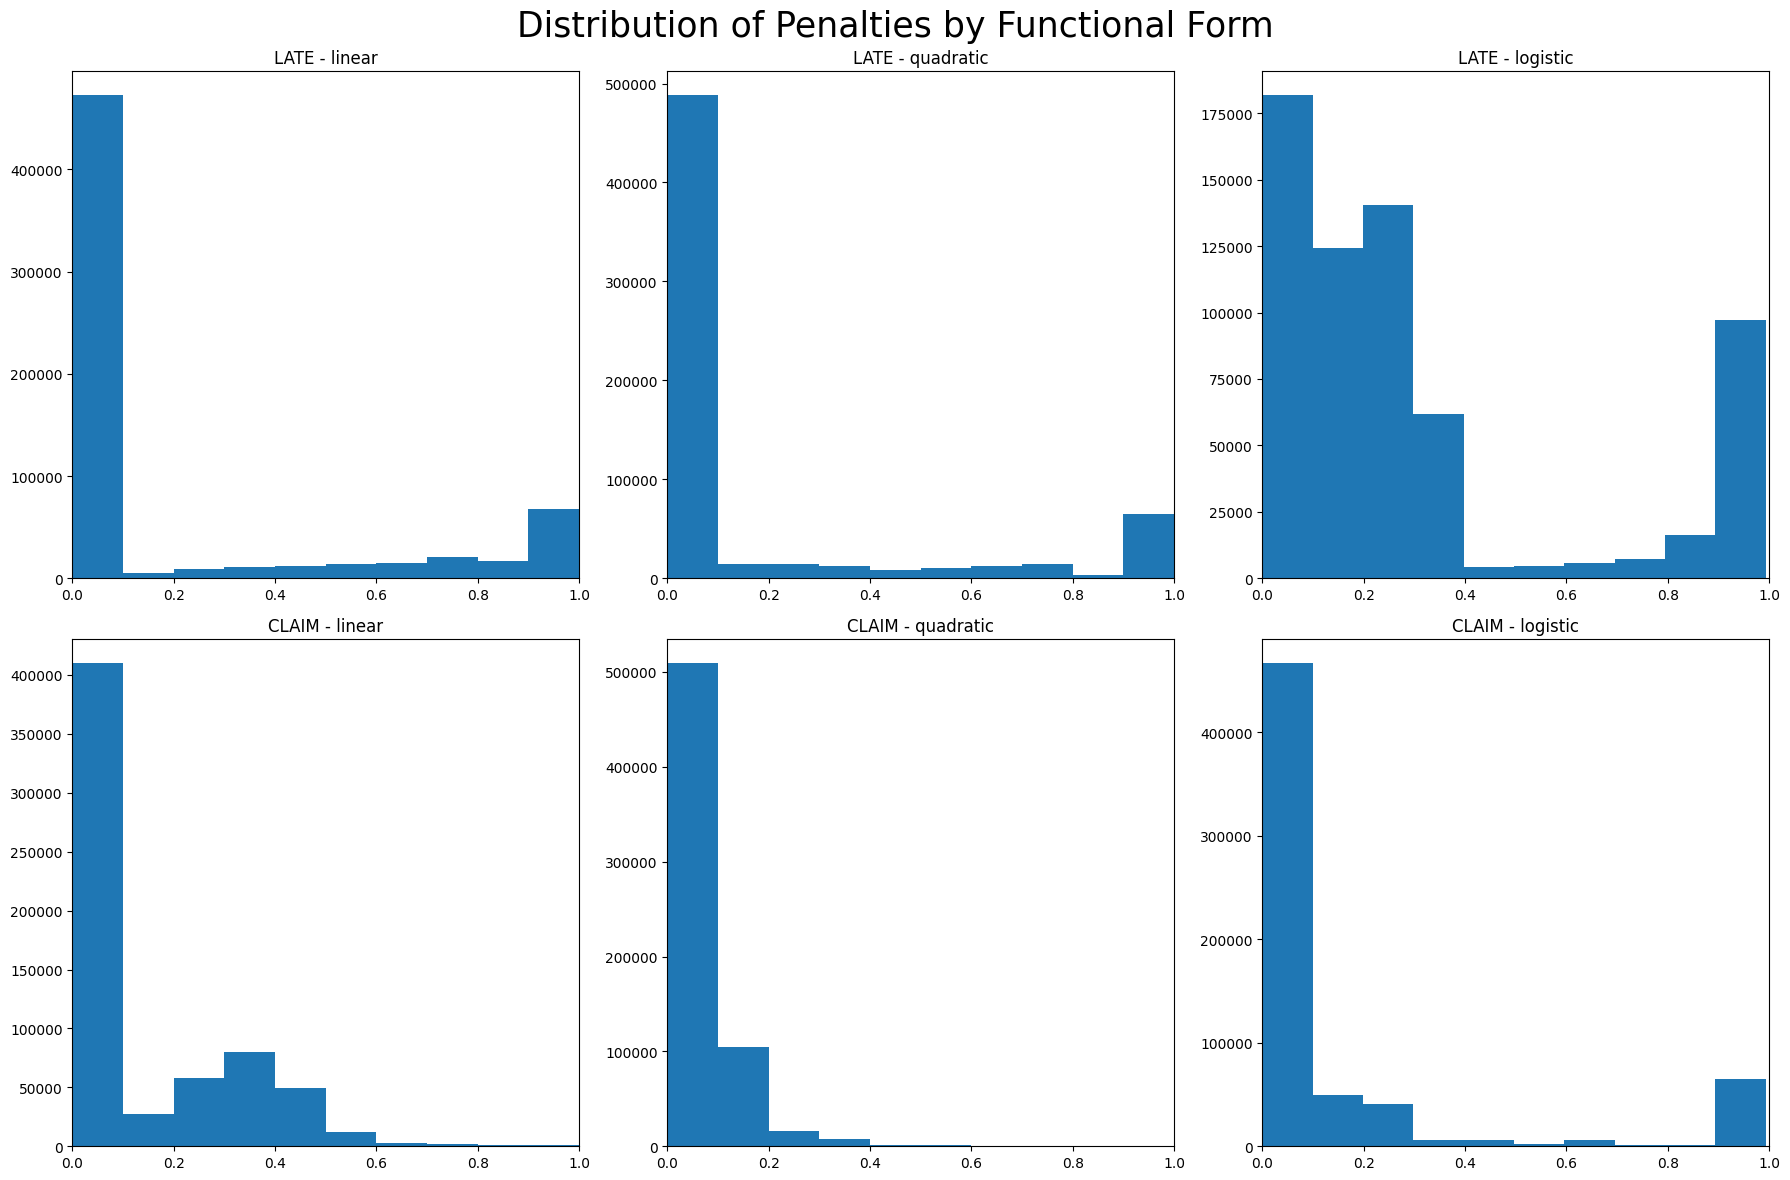

In [0]:
cols = [
    # late
    "late_capped_linear_penalty",
    "late_capped_quadratic_penalty",
    "late_capped_logistic_penalty",
    # Claim
    "claim_capped_linear_penalty",
    "claim_capped_quadratic_penalty",
    "claim_capped_logistic_penalty",
]

pdf = seller_index.select(cols).toPandas()

fig.suptitle(
    "Distribution of Penalties by Functional Form (above threshold)",
    fontsize=36
)




# Histograms
metrics = ["late", "claim"]
functions = ["linear", "quadratic", "logistic"]

fig, axes = plt.subplots(len(metrics), len(functions), figsize=(18, 12))


fig.suptitle(
    "Distribution of Penalties by Functional Form",
    fontsize=25
)

for i, metric in enumerate(metrics):
    for j, func in enumerate(functions):
        
        col_name = f"{metric}_capped_{func}_penalty"
        
        ax = axes[i, j]
        
        ax.hist(pdf[col_name].dropna(), bins=10)
        ax.set_title(f"{metric.upper()} - {func}")
        ax.set_xlim(0, 1)

plt.tight_layout()
plt.show()

In [0]:
display(fact_seller_metrics[fact_seller_metrics.late_rate > 0].count())

172712

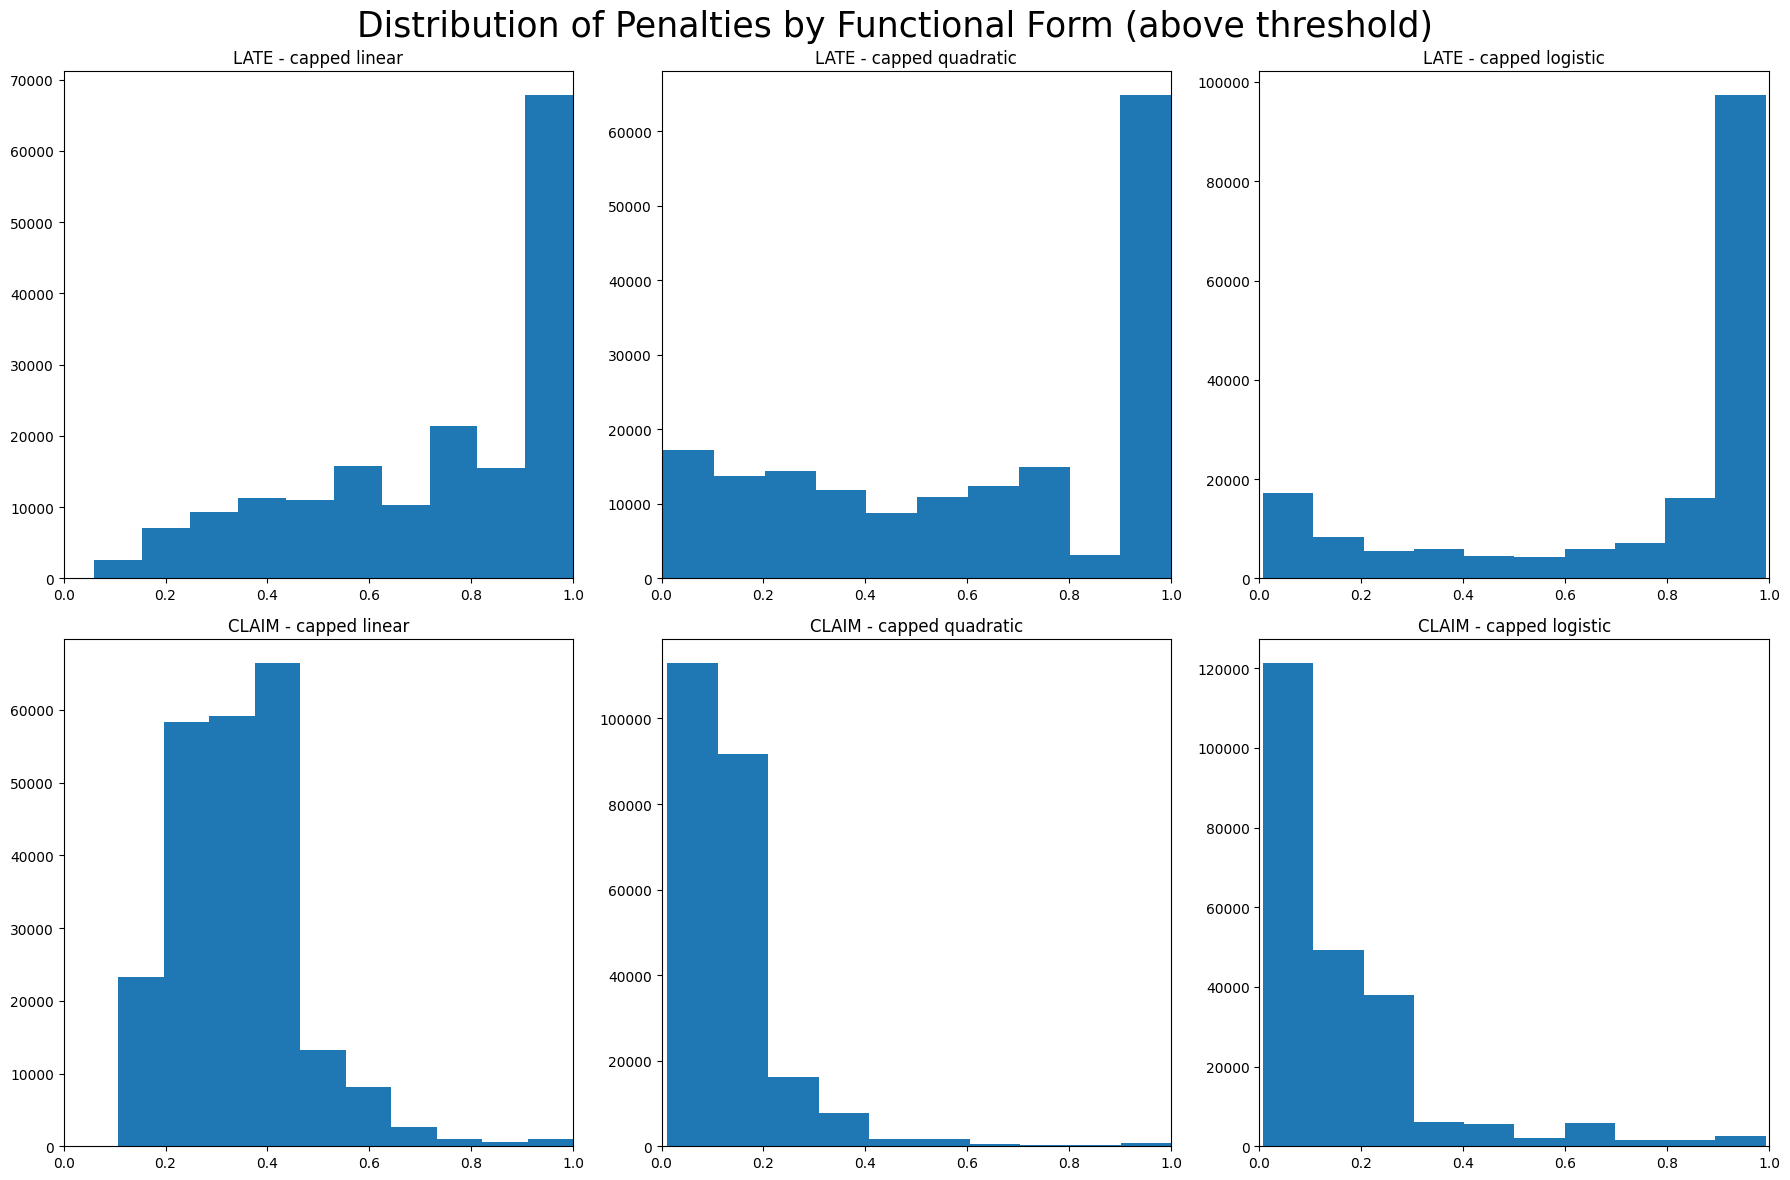

In [0]:
# DataFrames capped
pdf_late = seller_index[
    seller_index.late_rate > late_th
].select(
    "late_rate_capped",
    "late_capped_linear_penalty",
    "late_capped_quadratic_penalty",
    "late_capped_logistic_penalty"
).toPandas()


pdf_claim = seller_index[
    seller_index.claim_rate > claim_th
].select(
    "claim_rate_capped",
    "claim_capped_linear_penalty",
    "claim_capped_quadratic_penalty",
    "claim_capped_logistic_penalty"
).toPandas()


# Map
pdf_map = {
    "late": pdf_late,
    "claim": pdf_claim
}

# Histograms
metrics = ["late", "claim"]
functions = ["linear", "quadratic", "logistic"]

fig, axes = plt.subplots(len(metrics), len(functions), figsize=(18, 12))


fig.suptitle(
    "Distribution of Penalties by Functional Form (above threshold)",
    fontsize=25
)

for i, metric in enumerate(metrics):
    for j, func in enumerate(functions):
        
        col_name = f"{metric}_capped_{func}_penalty"
        pdf = pdf_map[metric]
        
        ax = axes[i, j]
        
        ax.hist(pdf[col_name].dropna(), bins=10)
        ax.set_title(f"{metric.upper()} - capped {func}")
        ax.set_xlim(0, 1)

plt.tight_layout()
plt.show()

For seller-days above the threshold, the average late penalty is 0.74 with the linear form, 0.61 with the quadratic and 0.75 with the logistic one. For claims, the averages are 0.35, 0.14 and 0.15.

The quadratic form reduces the penalty of moderate deviations, so it is the most permissive one. The logistic form depends on the distance to the threshold: for late shipments, where many sellers are far above the 1% target, its penalties are similar to the linear ones, while for claims, where most deviations are moderate, they are closer to the quadratic ones.

### Seller Index

In [0]:
# Index posibilities

seller_index = generate_seller_index(seller_index)

Values != 5 - Linear 231521
Values != 5 - Quadratic 149451
Values != 5 - Logistic 372103


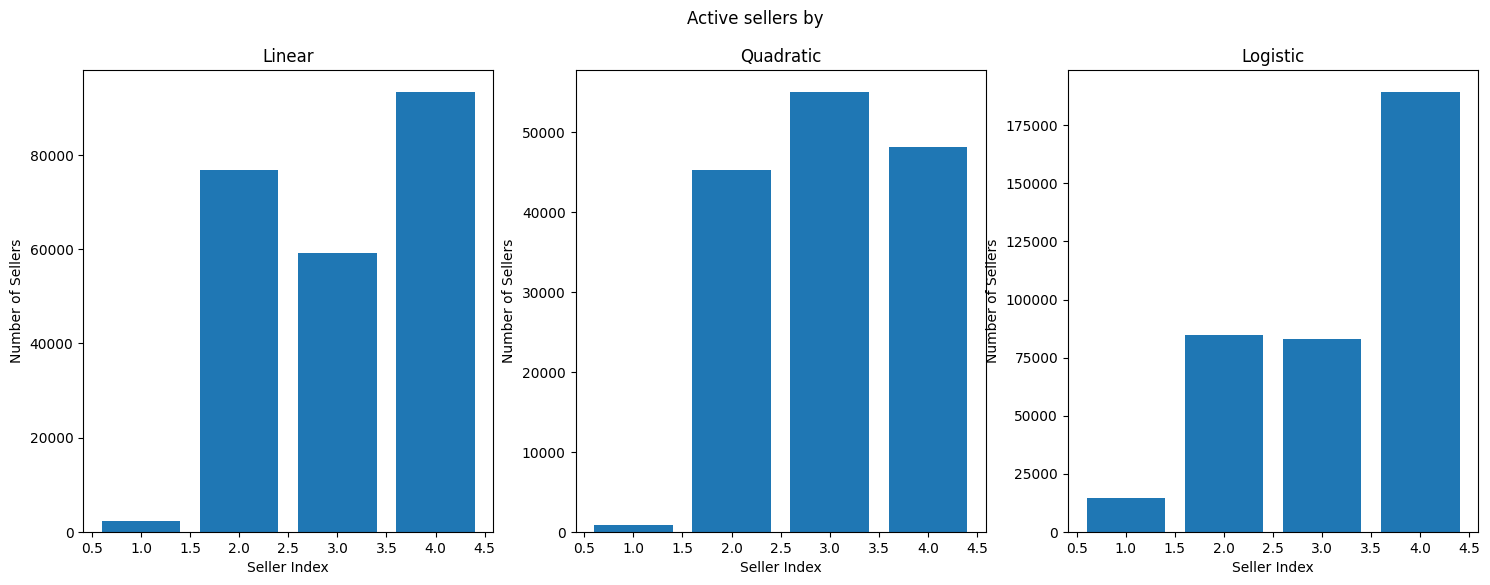

In [0]:
fig, axes = plt.subplots(1,3, figsize=(18,6))

# Linear
pdf = seller_index.filter(F.col("seller_index_linear") != 5).groupBy("seller_index_linear").count().toPandas()
print(f"Values != 5 - Linear {seller_index.filter(F.col('seller_index_linear') != 5).count()}")
axes[0].bar(pdf["seller_index_linear"], pdf["count"])
axes[0].set_title("Linear")
axes[0].set_xlabel("Seller Index")
axes[0].set_ylabel("Number of Sellers")

# Quadratic
pdf = seller_index.filter(F.col("seller_index_quadratic") != 5).groupBy("seller_index_quadratic").count().toPandas()
print(f"Values != 5 - Quadratic {seller_index.filter(F.col('seller_index_quadratic') != 5).count()}")

axes[1].bar(pdf["seller_index_quadratic"], pdf["count"])
axes[1].set_title("Quadratic")
axes[1].set_xlabel("Seller Index")
axes[1].set_ylabel("Number of Sellers")

# Logistic
pdf = seller_index.filter(F.col("seller_index_logistic") != 5).groupBy("seller_index_logistic").count().toPandas()

print(f"Values != 5 - Logistic {seller_index.filter(F.col('seller_index_logistic') != 5).count()}")


axes[2].bar(pdf["seller_index_logistic"], pdf["count"])
axes[2].set_title("Logistic")
axes[2].set_xlabel("Seller Index")
axes[2].set_ylabel("Number of Sellers")

fig.suptitle("Active sellers by ")
plt.show()

With the production parameters, the maximum score is obtained in 64% of seller-days with the linear index, 77% with the quadratic and 42% with the logistic one. The logistic index moves many sellers to a score of 4 (29% of seller-days, compared with 15% for the linear index), while the quadratic one penalizes fewer sellers.

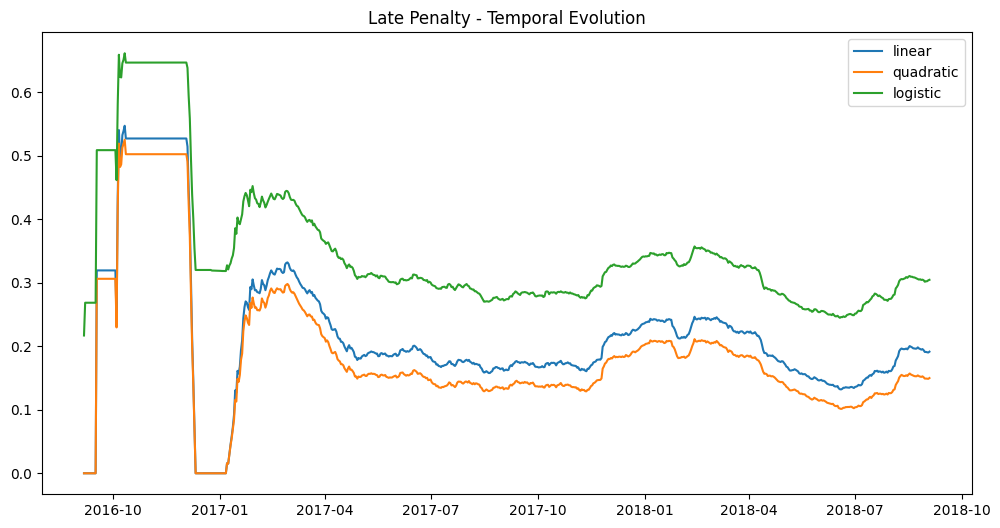

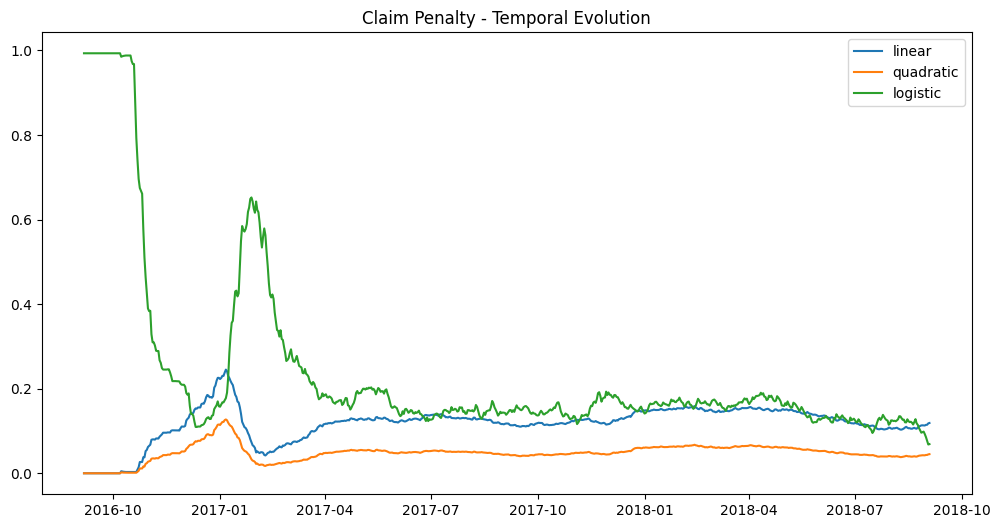

In [0]:
metrics = ["late", "claim"]
functions = ["linear", "quadratic", "logistic"]

for m in metrics:
    
    plt.figure(figsize=(12,6))
    
    for f in functions:
        
        col_name = f"{m}_capped_{f}_penalty"
        
        components_ts = (
            seller_index
            .groupBy("reference_date")
            .agg(
                F.avg(col_name).alias("value")
            )
        )

        comp_pd = components_ts.toPandas().sort_values(["reference_date"])
        
        # Serie temporal
        plt.plot(
            comp_pd["reference_date"], 
            comp_pd["value"], 
            label=f"{f}"
        )
        
        # Línea de media (tendencia simple)
        mean_val = comp_pd["value"].mean()
            
    plt.title(f"{m.capitalize()} Penalty - Temporal Evolution")
    plt.legend()
    plt.show()

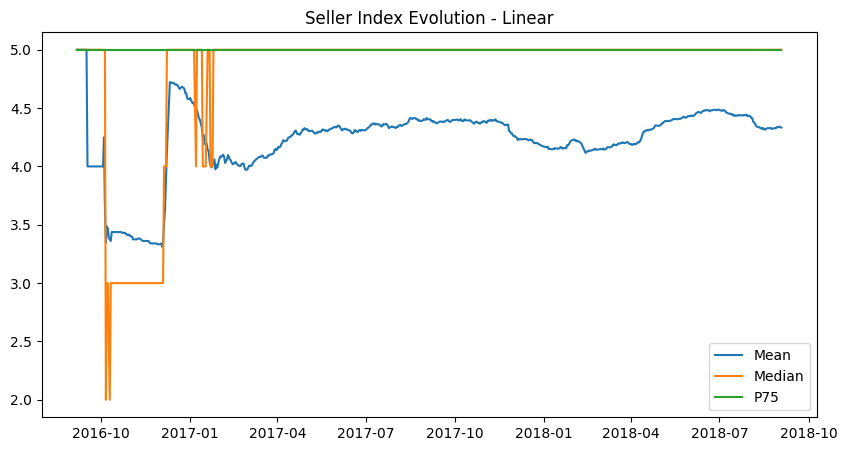

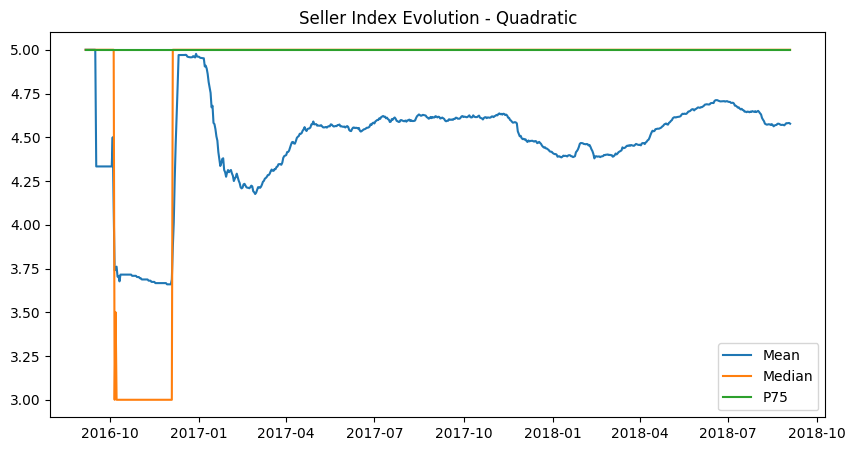

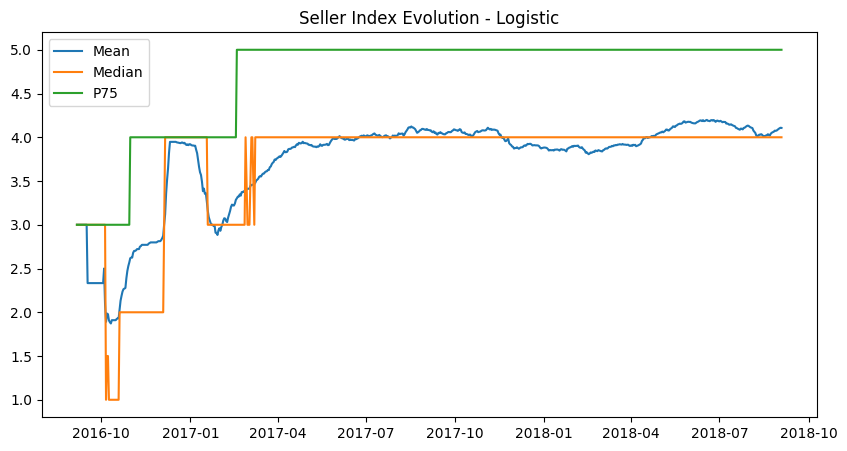

In [0]:
index_versions = ["linear", "quadratic", "logistic"]

for version in index_versions:
    
    col_name = f"seller_index_{version}"
    
    index_ts = (
        seller_index
        .groupBy("reference_date")
        .agg(
            F.avg(col_name).alias("avg_index"),
            F.expr(f"percentile({col_name}, array(0.5))[0]").alias("median_index"),
            F.expr(f"percentile({col_name}, array(0.75))[0]").alias("p75_index")
        )
    )

    index_pd = index_ts.toPandas().sort_values(["reference_date"])

    plt.figure(figsize=(10,5))
    plt.plot(index_pd["reference_date"], index_pd["avg_index"], label="Mean")
    plt.plot(index_pd["reference_date"], index_pd["median_index"], label="Median")
    plt.plot(index_pd["reference_date"], index_pd["p75_index"], label="P75")
    
    plt.legend()
    plt.title(f"Seller Index Evolution - {version.capitalize()}")
    plt.show()


The index is lower at the beginning of the period (late 2016 and early 2017), when there were few sellers and late rates were higher, and it stabilizes from mid-2017 (around 4.3-4.4 on average for the linear index). A temporary drop can be seen in early 2018, coinciding with an increase of late shipments across the marketplace.

### Financial Scenarios

In [0]:

fact_order_items = spark.table("marketplace_olist.gold.fact_order_items")

fact_order_items = fact_order_items.withColumn(
    "order_purchase_timestamp",
     F.to_date("order_purchase_ts")
     )

# Join with explicit column selection to avoid duplicates
fact_order_items = fact_order_items.alias("foi").join(
    seller_index.select(
        F.col("reference_date"),
        F.col("seller_key"),
        F.col("seller_index_linear"),
        F.col("seller_index_quadratic"),
        F.col("seller_index_logistic")
    ).alias("si"),
    (
        (F.col("foi.order_purchase_timestamp") == F.col("si.reference_date")) &
        (F.col("foi.seller_key") == F.col("si.seller_key"))
    ),
    how="left"
).select(
    "foi.*",
    "si.seller_index_linear",
    "si.seller_index_quadratic",
    "si.seller_index_logistic"
)

In [0]:
df = fact_order_items

# BASELINE FREIGHT COST SHARE (fixed 50/50 split between OLIST and seller when P <= 79)

df = (
    df
    .withColumn(
        "olist_shipping_pct_baseline",
        F.when(F.col("price") <= 79, 0.0)
         .otherwise(0.5)
    )
    .withColumn(
        "seller_shipping_pct_baseline",
        F.when(F.col("price") <= 79, 0.0)
         .otherwise(0.5)
    )
    .withColumn(
        "olist_shipping_value_baseline",
        F.round(
            F.col("olist_shipping_pct_baseline") * F.col("freight_value"),
            2
        )
    )
    .withColumn(
        "seller_shipping_value_baseline",
        F.round(
            F.col("seller_shipping_pct_baseline") * F.col("freight_value"),
            2
        )
    )
)


# Client share of freight cost
df = df.withColumn(
    "client_shipping_pct",
    F.when(F.col("price") <= 79, 1.0).otherwise(0.0)
).withColumn(
    "client_shipping_value",
    F.col("client_shipping_pct") * F.col("freight_value")
)


In [0]:

def add_shipping_split(df, index_type):
    '''
    Applies the freight cost split logic based on the seller index type
    '''
    
    index_col = f"seller_index_{index_type}"
    
    olist_pct_col = f"olist_shipping_pct_{index_type}"
    seller_pct_col = f"seller_shipping_pct_{index_type}"
    
    olist_val_col = f"olist_shipping_value_{index_type}"
    seller_val_col = f"seller_shipping_value_{index_type}"
    
    # % share OLIST
    df = df.withColumn(
        olist_pct_col,
        F.when(F.col("price") <= 79, 0.0)
         .when(F.col(index_col).isNull(), 0.5)    # sellers without index keep the 50/50 split
         .when(F.col(index_col) == 5, 0.5)
         .when(F.col(index_col) == 4, 0.4)
         .when(F.col(index_col) == 3, 0.3)
         .when(F.col(index_col) == 2, 0.15)
         .when(F.col(index_col) == 1, 0.15)
         .otherwise(0.0)
    )
    
    # % share SELLER
    df = df.withColumn(
        seller_pct_col,
        F.when(F.col("price") <= 79, 0.0)
         .otherwise(1.0 - F.col(olist_pct_col))
    )
    
    # Values
    df = df.withColumn(
        olist_val_col,
        F.round(
            F.col(olist_pct_col) * F.col("freight_value"),
             2)
    )
    
    df = df.withColumn(
        seller_val_col,
        F.when(F.col("price") <= 79, 0.0).otherwise(
            F.round(
                F.col("freight_value") - F.col(olist_val_col)
                ,2
            )
        )
    )
    
    return df

In [0]:
index_types = ["linear", "quadratic", "logistic"]

# Loop for various index models

for idx in index_types:
    df = add_shipping_split(df, idx)

fact_order_items = df

In [0]:
df_monthly = (
    fact_order_items
    .withColumn("month", F.date_trunc("month", F.col("order_purchase_ts")))
    .groupBy("month")
    .agg(
        F.sum("olist_shipping_value_baseline").alias("olist_baseline"),
        F.sum("olist_shipping_value_linear").alias("olist_linear"),
        F.sum("olist_shipping_value_quadratic").alias("olist_quadratic"),
        F.sum("olist_shipping_value_logistic").alias("olist_logistic")
    )
    .orderBy("month")
)

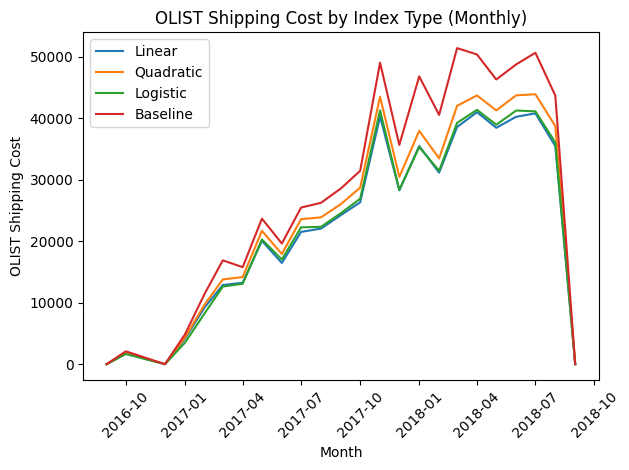

In [0]:

pdf = df_monthly.toPandas()

plt.figure()

plt.plot(pdf["month"], pdf["olist_linear"], label="Linear")
plt.plot(pdf["month"], pdf["olist_quadratic"], label="Quadratic")
plt.plot(pdf["month"], pdf["olist_logistic"], label="Logistic")
plt.plot(pdf["month"], pdf["olist_baseline"], label="Baseline")

plt.legend()
plt.xlabel("Month")
plt.ylabel("OLIST Shipping Cost")
plt.title("OLIST Shipping Cost by Index Type (Monthly)")

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [0]:
df_monthly.createOrReplaceTempView("df_monthly")

result = spark.sql("""
    SELECT 
        ROUND(SUM(olist_baseline),2) as baseline_cost,
        ROUND(SUM(olist_linear),2) as linear_cost,
        ROUND(SUM(olist_quadratic),2) as quadratic_cost,
        ROUND(SUM(olist_logistic),2) as logistic_cost
    FROM df_monthly
""")

display(result)

baseline_cost,linear_cost,quadratic_cost,logistic_cost
669003.92,541322.62,584059.93,546636.37


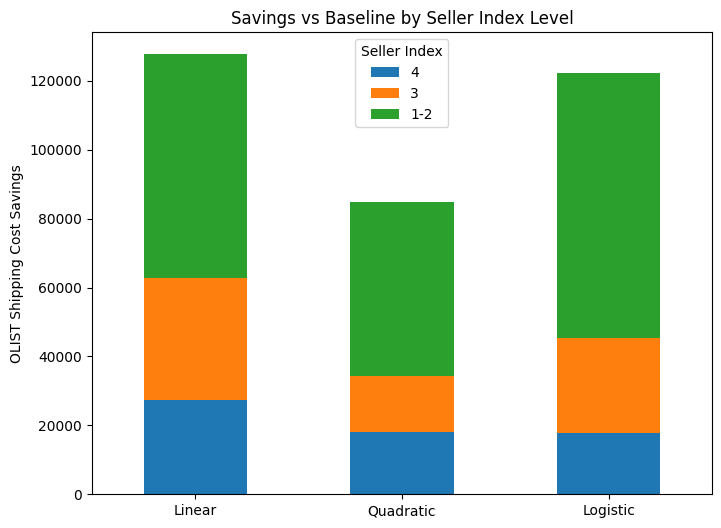

In [0]:
# Savings vs baseline by seller index level

levels = ["4", "3", "1-2"]

savings_by_level = pd.DataFrame()

for idx in index_types:

    pdf = (
        fact_order_items
        .filter(F.col(f"seller_index_{idx}") < 5)
        .withColumn(
            "level",
            F.when(F.col(f"seller_index_{idx}") <= 2, "1-2")
             .otherwise(F.col(f"seller_index_{idx}").cast("int").cast("string"))
        )
        .groupBy("level")
        .agg(
            F.sum(F.col("olist_shipping_value_baseline") - F.col(f"olist_shipping_value_{idx}")).alias("savings")
        )
        .toPandas()
        .set_index("level")
    )

    savings_by_level[idx.capitalize()] = pdf["savings"].reindex(levels).fillna(0)

savings_by_level.T.plot(kind="bar", stacked=True, figsize=(8, 6))

plt.title("Savings vs Baseline by Seller Index Level")
plt.ylabel("OLIST Shipping Cost Savings")
plt.xticks(rotation=0)
plt.legend(title="Seller Index")
plt.show()

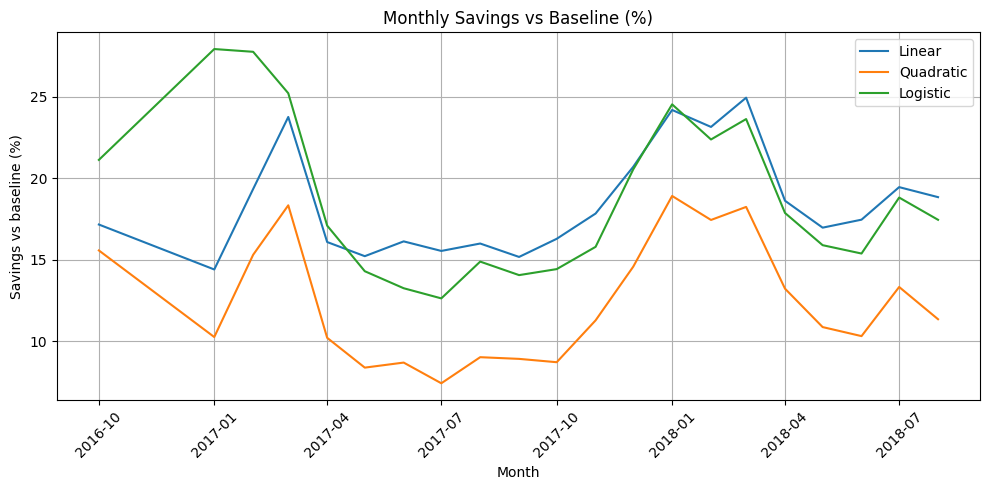

In [0]:
# Monthly savings as % of the baseline cost

pdf = df_monthly.toPandas()
pdf = pdf[pdf["olist_baseline"] > 1000]    # months with very few orders (start and end of the data) are excluded

plt.figure(figsize=(10, 5))

for idx in index_types:
    savings_pct = 100 * (pdf["olist_baseline"] - pdf[f"olist_{idx}"]) / pdf["olist_baseline"]
    plt.plot(pdf["month"], savings_pct, label=idx.capitalize())

plt.legend()
plt.xlabel("Month")
plt.ylabel("Savings vs baseline (%)")
plt.title("Monthly Savings vs Baseline (%)")
plt.xticks(rotation=45)
plt.grid()
plt.tight_layout()
plt.show()

With the production parameters, most of the savings come from sellers with an index of 1-2 (51% of the savings of the linear index), followed by sellers with 3 (28%) and 4 (21%). In relative terms, the linear index reduces OLIST's shipping cost by 14-25% every month. The highest savings are concentrated between December 2017 and March 2018, the same period in which the index dropped because of the increase of late shipments.

## 5.4 - Choosing the index version

The three versions of the index are built with the same metrics and parameters, so choosing one of them is a policy decision. To make it explicit, the following criteria are applied in order:

1. **Validity**: the index must rank sellers by risk. Sellers with a lower index today should have a higher late rate in the following 60 days.
2. **Fairness with low-volume sellers**: in line with the purpose of the Bayesian smoothing, sellers with few orders should not be penalized more often than high-volume sellers.
3. **Stability**: the index should not change too often (as a reference, less than once per seller and month), so sellers can understand it and react to it.
4. **Differentiation and savings**: among the versions that meet the previous criteria, the preferred one keeps the maximum score for a majority of sellers, but not for almost all of them, and generates the highest savings for OLIST.

The future late rate is calculated for each seller and reference date with the orders placed in the following 60 days, which are not used to calculate the index.

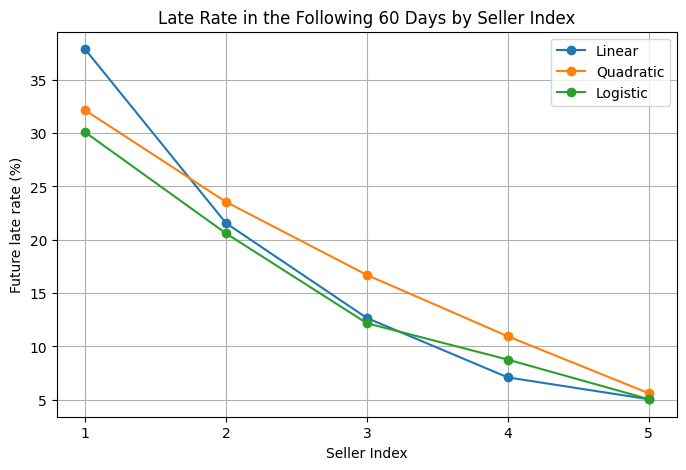

In [0]:
# Late rate in the 60 days after each reference date

daily_late = (
    pit_orders
    .groupBy("seller_key", "order_date")
    .agg(
        F.sum("delivered_to_carrier_flag").alias("delivered"),
        F.sum("late_to_carrier_flag").alias("late")
    )
    .withColumnRenamed("order_date", "reference_date")
)

future = (
    dense_calendar
    .select("seller_key", "reference_date")
    .join(daily_late, ["seller_key", "reference_date"], "left")
    .fillna(0)
    .withColumn("ref_day", F.datediff(F.col("reference_date"), F.lit("1970-01-01")))
)

future_window = Window.partitionBy("seller_key").orderBy("ref_day").rangeBetween(1, 60)

future = (
    future
    .withColumn("future_delivered", F.sum("delivered").over(future_window))
    .withColumn("future_late", F.sum("late").over(future_window))
    .select("seller_key", "reference_date", "future_delivered", "future_late")
)

seller_index_future = seller_index.join(future, ["seller_key", "reference_date"], "left")

# Validity: future late rate by index value

plt.figure(figsize=(8, 5))

for idx in index_types:

    pdf = (
        seller_index_future
        .groupBy(f"seller_index_{idx}")
        .agg((F.sum("future_late") / F.sum("future_delivered")).alias("future_late_rate"))
        .toPandas()
        .sort_values(f"seller_index_{idx}")
    )

    plt.plot(pdf[f"seller_index_{idx}"], 100 * pdf["future_late_rate"], marker="o", label=idx.capitalize())

plt.title("Late Rate in the Following 60 Days by Seller Index")
plt.xticks([1, 2, 3, 4, 5])
plt.xlabel("Seller Index")
plt.ylabel("Future late rate (%)")
plt.legend()
plt.grid()
plt.show()

In [0]:
# Comparison table

lag_window = Window.partitionBy("seller_key").orderBy("reference_date")
orders_col = f"orders_{window_days}d"

comparison_df = seller_index_future.withColumn("prev_date", F.lag("reference_date").over(lag_window))

for idx in index_types:
    comparison_df = comparison_df.withColumn(f"prev_{idx}", F.lag(f"seller_index_{idx}").over(lag_window))

aggs = []

for idx in index_types:
    col = F.col(f"seller_index_{idx}")
    aggs += [
        F.avg((col == 5).cast("int")).alias(f"{idx}_pct_5"),
        (F.sum(F.when(col == 5, F.col("future_late"))) / F.sum(F.when(col == 5, F.col("future_delivered")))).alias(f"{idx}_late_5"),
        (F.sum(F.when(col <= 2, F.col("future_late"))) / F.sum(F.when(col <= 2, F.col("future_delivered")))).alias(f"{idx}_late_1_2"),
        F.avg(F.when(F.datediff("reference_date", "prev_date") == 1, (col != F.col(f"prev_{idx}")).cast("int"))).alias(f"{idx}_changes"),
        F.avg(F.when(F.col(orders_col) <= 3, (col <= 3).cast("int"))).alias(f"{idx}_low_volume"),
        F.avg(F.when(F.col(orders_col) >= 20, (col <= 3).cast("int"))).alias(f"{idx}_high_volume"),
    ]

stats = comparison_df.agg(*aggs).first()

costs = fact_order_items.agg(
    F.sum("olist_shipping_value_baseline").alias("baseline"),
    F.sum("olist_shipping_value_linear").alias("linear"),
    F.sum("olist_shipping_value_quadratic").alias("quadratic"),
    F.sum("olist_shipping_value_logistic").alias("logistic")
).first()

rows = []

for idx in index_types:
    rows.append({
        "Index": idx.capitalize(),
        "Future late rate - index 5 (%)": round(100 * stats[f"{idx}_late_5"], 1),
        "Future late rate - index 1-2 (%)": round(100 * stats[f"{idx}_late_1_2"], 1),
        "Low-volume seller-days (<=3 orders) with index <=3 (%)": round(100 * stats[f"{idx}_low_volume"], 1),
        "High-volume seller-days (>=20 orders) with index <=3 (%)": round(100 * stats[f"{idx}_high_volume"], 1),
        "Index changes per seller and month": round(30 * stats[f"{idx}_changes"], 2),
        "Seller-days with index 5 (%)": round(100 * stats[f"{idx}_pct_5"], 1),
        "OLIST shipping cost": round(costs[idx]),
        "Savings vs baseline": round(costs["baseline"] - costs[idx]),
        "Savings vs baseline (%)": round(100 * (costs["baseline"] - costs[idx]) / costs["baseline"], 1),
    })

comparison = pd.DataFrame(rows).set_index("Index").T
comparison

Index,Linear,Quadratic,Logistic
Future late rate - index 5 (%),5.10,5.60,5.10
Future late rate - index 1-2 (%),22.20,23.70,21.40
Low-volume seller-days (<=3 orders) with index <=3 (%),15.20,15.20,29.90
High-volume seller-days (>=20 orders) with index <=3 (%),30.40,17.50,25.20
Index changes per seller and month,0.52,0.41,0.87
Seller-days with index 5 (%),64.00,76.80,42.20
OLIST shipping cost,541323.00,584060.00,546636.00
Savings vs baseline,127681.00,84944.00,122368.00
Savings vs baseline (%),19.10,12.70,18.30


With the production parameters, the three versions pass the validity test: the late rate in the following 60 days decreases as the index increases, from 21-24% for sellers with an index of 1-2 to around 5% for sellers with 5.

The logistic index does not meet the second criterion: 30% of the seller-days with 3 or fewer orders get an index of 3 or lower, compared with 25% of the seller-days with 20 or more orders. It is also the least stable version (0.87 changes per seller and month).

The linear and quadratic versions meet the first three criteria. The quadratic index gives the maximum score to 77% of seller-days and generates the lowest savings (13% of the baseline cost). The linear index keeps the maximum score for 64% of seller-days, separates risk slightly better and generates the highest savings (19%).

**The linear index is therefore the selected version.**

# Conclusion

## Conclusion

The introduction of the Seller Index serves a dual purpose. First, it aligns seller behavior with OLIST's operational objectives by encouraging better delivery performance and fewer claims. Second, it helps reduce the transportation costs currently shared between OLIST and its sellers (50/50 split) by replacing a flat cost structure with an incentive-based mechanism that rewards operational excellence.

The comparison of the three versions (section 5.4) shows that all of them identify the sellers with a higher risk of late shipments, but they distribute the penalties differently. The logistic version penalizes low-volume sellers more often than high-volume ones, which goes against one of the design principles of the index, and the quadratic version gives the maximum score to almost four out of five sellers. The linear version offers the best balance between seller incentives, metric sensitivity and savings, and it is the selected one.

Under a ceteris paribus scenario and with the production parameters, the linear index would reduce OLIST's shipping costs by around R$128,000 over the analyzed period of approximately two years, 19% of the cost under the current 50/50 split, with monthly savings between 14% and 25%. Sellers without an index keep the current split, so these savings are not obtained at the expense of new sellers.

Beyond the direct financial impact, the Seller Index provides a scalable framework to promote seller accountability and continuously improve marketplace performance, creating a stronger alignment between operational outcomes and economic incentives.